# JalanKu — Notebook 03: Evaluasi

## Tujuan notebook ini
Notebook ini menyajikan hasil evaluasi model JalanKu: protokol yang dipakai (model dan ambang dikunci dari val sebelum test dibuka),
perbandingan semua model pada val, pemilihan ambang per kelas, matriks konfusi, hasil **test set** (91 frame di lokasi yang belum pernah dilihat model)
untuk model kotak dan segmentasi, penurunan dari val ke test beserta penjelasannya, dan contoh kualitatif. Notebook ini **hanya membaca**
hasil yang sudah tersimpan (`data/test-final/`, `docs/`, `runs/`); test set dievaluasi **satu kali** dan terkunci, jadi tidak ada evaluasi baru,
pelatihan, atau inferensi model di sini. Satu-satunya perhitungan ulang adalah matriks konfusi dari prediksi yang sudah tersimpan
(bagian 8), yang dicocokkan lebih dulu dengan angka TP/FP/FN yang tercatat sebelum dipakai. Semua angka dihitung dari berkas oleh sel kode,
bukan diketik manual, dan setiap bagian ditutup dengan "Bacaan" yang menyebutkan juga kelemahannya.

## 0. Persiapan
Sel di bawah menentukan akar repo, memeriksa berkas sumber, dan menyiapkan fungsi pembantu. Fungsi pencocokan kotak dan pembacaan label
dipakai ulang dari `tools/` (modul-modul itu tidak memuat torch; sel ini memeriksanya). Folder `data/`, `runs/`, dan `models/` tidak masuk Git.

In [1]:
import csv, json, re, io, html, collections, pickle, sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML, Markdown, Image as IPImage

# ROOT = akar repo (induk folder notebooks/); dicari ke atas dari folder kerja
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "data"
TF = DATA / "test-final"

def rel(p):
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return Path(p).name

def baca(p):
    return Path(p).read_text(encoding="utf-8", errors="replace")

def baca_json(p):
    return json.loads(baca(p))

def baca_csv(p):
    with open(p, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

WAJIB = [
    "docs/hasil-test-final.md", "data/test-final/LOG.md", "data/test-final/t1", "data/test-final/t1/tabel.md",
    "data/test-final/t1_val", "data/test-final/ambang_val_ens.json", "data/test-final/ambang_kurva_val_ens.csv",
    "data/test-final/ens_banding_val.json", "data/test-final/ens_kecepatan_protokol.json", "data/test-final/r4_banding_val_final.json",
    "data/test-final/metrik_tambahan_val.json", "data/test-final/val_recall_dekat_ens.json",
    "data/test-final/t1/pred_C2.pkl", "data/test-final/t1_val/pred_C2.pkl",
    "data/dataset-test-kotak/data.yaml", "data/dataset-test-kotak/labels", "data/dataset-gabung-kotak-v2/data.yaml",
    "runs/ronde2/r2-kotak-v3-960/confusion_matrix_normalized.png", "runs/test-final/C2_kontak_16.jpg", "data/test-final/before_after_val.jpg",
    "tools/test_t1.py",
]
hilang = [w for w in WAJIB if not (ROOT / w).exists()]
if hilang:
    print("BERKAS TIDAK DITEMUKAN (data/, runs/, models/ tidak ikut Git):")
    for w in hilang:
        print("  -", w)
    print("Notebook ini hanya bisa dijalankan ulang di laptop yang memiliki folder tersebut.")
    print("Di tempat lain, lihat saja keluaran yang sudah tersimpan di notebook.")
else:
    print("Semua", len(WAJIB), "berkas/folder sumber ditemukan. ROOT = (akar repo)")

# fungsi pencocokan dari tools/ (tanpa menulis bytecode ke tools/, tanpa torch)
sys.dont_write_bytecode = True
sys.path.insert(0, str(ROOT / "tools"))
import evaluasi_baseline as eb
import evaluasi_ronde2 as er
import test_final as tf
import metrik_tambahan as mt
import test_t1 as t1m
print("torch dimuat?", "torch" in sys.modules, "| ultralytics dimuat?", "ultralytics" in sys.modules)
assert "torch" not in sys.modules and "ultralytics" not in sys.modules

# --- pembantu tampilan ---------------------------------------------------------------------
def tabel(kepala, baris, rata_kanan=None):
    rata_kanan = set(rata_kanan or [])
    h = "<table style='border-collapse:collapse;font-size:90%'>"
    h += "<tr>" + "".join(f"<th style='border:1px solid #888;padding:3px 8px;background:#eee;color:#000'>{html.escape(str(c))}</th>" for c in kepala) + "</tr>"
    for r in baris:
        h += "<tr>"
        for i, c in enumerate(r):
            al = "right" if i in rata_kanan else "left"
            h += f"<td style='border:1px solid #888;padding:3px 8px;text-align:{al}'>{html.escape(str(c))}</td>"
        h += "</tr>"
    display(HTML(h + "</table>"))

def kutipan(teks):
    display(HTML("<blockquote style='border-left:4px solid #888;margin:6px 0;padding:4px 12px;font-size:90%'>"
                 + html.escape(teks) + "</blockquote>"))

def f3(x, n=3):
    return "-" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{n}f}"

def rs(d):
    # {gt, ditemukan, recall} -> "ditemukan/gt (recall)"
    return "0/0" if not d["gt"] else f"{d['ditemukan']}/{d['gt']} ({d['recall']:.2f})"

def tpfpfn(d):
    return f"{d['tp']}/{d['fp']}/{d['fn']}"

# --- daftar putih privasi untuk gambar berkas ----------------------------------------------
GAMBAR_TAMPIL = []
PUTIH = [
    re.compile(r"^runs/(baseline|ronde2|test-final)/[^/]+/(results\.png|[A-Za-z]*_curve\.png|confusion_matrix[a-z_]*\.png|labels\.jpg|train_batch\d+\.jpg|val_batch\d+(_labels|_pred)?\.jpg)$"),
    re.compile(r"^runs/test-final/(C2_kontak_16|r2-seg-v3_kontak_16)\.jpg$"),
    re.compile(r"^data/test-final/(before_after_val\.jpg|val_fp_tangga[\w-]*\.png)$"),
]
def cek_putih(p):
    r = rel(p)
    assert any(x.match(r) for x in PUTIH), f"gambar di luar daftar putih privasi: {r}"
    assert "rumah" not in r.lower(), r
    GAMBAR_TAMPIL.append(r)

def tampil_jpeg(gambar_pil, lebar=1000, mutu=82):
    if gambar_pil.size[0] > lebar:
        gambar_pil = gambar_pil.resize((lebar, int(gambar_pil.size[1] * lebar / gambar_pil.size[0])), Image.LANCZOS)
    buf = io.BytesIO()
    gambar_pil.convert("RGB").save(buf, "JPEG", quality=mutu)
    display(IPImage(data=buf.getvalue(), format="jpeg"))

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("Siap.")

Semua 21 berkas/folder sumber ditemukan. ROOT = (akar repo)
torch dimuat? False | ultralytics dimuat? False
Siap.


### Memuat hasil tersimpan
Hasil per model ada di `data/test-final/t1/<model>.json` (test) dan `data/test-final/t1_val/<model>.json` (val, **jalur kode yang sama**),
jadi angka val dan test dapat dibandingkan langsung. Urutan model mengikuti `tools/test_t1.py`.

In [2]:
KOTAK = list(t1m.KOTAK)
SEG = list(t1m.SEG)
T = {n: baca_json(TF / "t1" / f"{n}.json") for n in KOTAK + SEG}
V = {n: baca_json(TF / "t1_val" / f"{n}.json") for n in KOTAK + SEG}
TS = lambda n, s="semua": T[n]["subset"][s]
VS = lambda n, s="semua": V[n]["subset"][s]
FINAL_K, FINAL_S = "C2", "r2-seg-v3"
PEMBANDING = "r2-kotak-v3-960"                      # final sebelum ensemble

NAMA_K, IMGS_TEST, LAB_TEST = eb.info_val(DATA / "dataset-test-kotak/data.yaml")
_, IMGS_VAL, LAB_VAL = eb.info_val(er.YK)
NAMES = [NAMA_K[i] for i in range(len(NAMA_K))]
AMBANG = baca_json(TF / "ambang_val_ens.json")
CK = AMBANG["conf_kelas"]
AMB_ID = {i: CK[n] for i, n in NAMA_K.items()}
print("Model kotak :", KOTAK)
print("Model seg   :", SEG)
print("Frame test:", len(IMGS_TEST), "| frame val:", len(IMGS_VAL), "| kelas kotak:", NAMES)
print("Ambang per kelas terkunci (C2):", CK)

Model kotak : ['baseline-kotak', 'r2-kotak-v2bersih', 'r2-kotak-v3', 'r2-kotak-v3-960', 'r3-kotak-v3-960-s', 'r4-kotak-v3-960-seed1', 'r4-kotak-v3-1280', 'r4-kotak-v4-960', 'C1', 'C2']
Model seg   : ['baseline-seg', 'r2-seg-v3', 'r4-seg-v4']
Frame test: 91 | frame val: 54 | kelas kotak: ['pilar', 'pohon', 'tepian', 'orang', 'tanaman_pot', 'kursi', 'kendaraan', 'tangga']
Ambang per kelas terkunci (C2): {'pilar': 0.25, 'pohon': 0.25, 'tepian': 0.2, 'orang': 0.6, 'tanaman_pot': 0.25, 'kursi': 0.25, 'kendaraan': 0.1, 'tangga': 0.25}


## 1. Protokol evaluasi
Urutan kerja yang menjaga test tetap jujur:
1. Model final dan semua ambang dikunci dari **val saja** sebelum ada satu pun angka test (baris kunci di paling atas `LOG.md`).
2. Aturan pemilihan tiap ronde ditulis ke LOG sebelum hasilnya ada (lihat Notebook 02, bagian 3).
3. Cara mengukur test (`[T1-ATURAN]`) ditulis sebelum test disentuh, jalur kodenya diuji dulu di val sampai semua angka val yang sudah tercatat keluar persis sama (`[T1-UJI-VAL]`), baru test dijalankan **satu kali** per model.
4. Tidak ada model, ambang, label, atau config yang diubah sesudah test. Isi gambar dan label test dibandingkan lewat SHA-256 sebelum dan sesudah.

Kutipan di bawah diambil langsung dari `LOG.md` oleh kode.

In [3]:
LOG = baca(TF / "LOG.md")
def entri(tag):
    for ln in LOG.splitlines():
        if ln.startswith(f"- [{tag}]"):
            return ln
    raise KeyError(tag)

kunci = next(l for l in LOG.splitlines() if l.startswith("MODEL FINAL DIKUNCI ULANG") and "ensemble" in l)
print("Baris kunci model final (paling atas LOG.md, sebelum angka test):")
kutipan(kunci[:700] + (" ..." if len(kunci) > 700 else ""))
ln_ar = entri("T1-ATURAN")
i0 = ln_ar.index("Skrip tools/test_t1.py")
j0 = ln_ar.index("tidak dijalankan ulang.", i0) + len("tidak dijalankan ulang.")
print("Aturan cara mengukur test ([T1-ATURAN], ditulis sebelum test disentuh):")
kutipan(ln_ar[i0:j0])
h_sebelum = re.search(r"sha256 ([0-9a-f]+)", entri("T1-0")).group(1)
h_sesudah = re.search(r"sha256 ([0-9a-f]+)", entri("T1-9")).group(1)
print(f"SHA-256 gambar+label test sebelum: {h_sebelum} | sesudah: {h_sesudah} -> {'SAMA' if h_sebelum == h_sesudah else 'BERBEDA'}")

print()
print("Pengaturan pengukuran (dibaca dari tools/, bukan diketik):")
tabel(["Pengaturan", "Nilai", "Dipakai untuk"], [
    ["IoU pencocokan kotak", eb.IOU, "TP/FP/FN: kelas sama dan IoU >= nilai ini"],
    ["conf seragam", eb.CONF, "perbandingan semua model pada titik kerja yang sama"],
    ["conf prediksi app", tf.CONF_PRED, "metrik berambang (TP/FP/FN, dekat, frame); C2: conf anggota lalu WBF"],
    ["batas 'dekat' (y2 / tinggi gambar)", tf.Y_DEKAT, "objek dekat = tepi bawah kotak GT di bawah garis ini"],
    ["pita tengah peringatan frame (x / lebar)", f"{mt.X_PITA[0]} - {mt.X_PITA[1]}", "frame positif = ada kotak dekat yang menimpa pita ini"],
])

Baris kunci model final (paling atas LOG.md, sebelum angka test):


Aturan cara mengukur test ([T1-ATURAN], ditulis sebelum test disentuh):


SHA-256 gambar+label test sebelum: 9d7721fcc7589bd6 | sesudah: 9d7721fcc7589bd6 -> SAMA

Pengaturan pengukuran (dibaca dari tools/, bukan diketik):


Pengaturan,Nilai,Dipakai untuk
IoU pencocokan kotak,0.5,TP/FP/FN: kelas sama dan IoU >= nilai ini
conf seragam,0.25,perbandingan semua model pada titik kerja yang sama
conf prediksi app,0.05,"metrik berambang (TP/FP/FN, dekat, frame); C2: conf anggota lalu WBF"
batas 'dekat' (y2 / tinggi gambar),0.65,objek dekat = tepi bawah kotak GT di bawah garis ini
pita tengah peringatan frame (x / lebar),0.33 - 0.67,frame positif = ada kotak dekat yang menimpa pita ini


### Definisi metrik
- **Precision** = TP / (TP + FP); **Recall** = TP / (TP + FN); **F1** = 2TP / (2TP + FP + FN). TP: kotak prediksi yang cocok dengan satu GT (kelas sama, IoU >= 0,5); FP: prediksi tanpa GT; FN: GT tanpa prediksi.
- **mAP50 / mAP50-95**: rata-rata AP per kelas pada IoU 0,5 / rata-rata IoU 0,5 sampai 0,95, dari prediksi conf rendah (0,001) lewat satu jalur kode untuk semua model ("jalur sendiri"). Kelas tanpa GT tidak dihitung.
- **F1 "jalur sendiri"** = rata-rata F1 per kelas pada satu conf global terbaik (definisi tabel Ultralytics). **F1 mikro** = F1 dari total TP/FP/FN pada ambang tertentu. Keduanya muncul di notebook ini; angka acuan F1 di bawah adalah yang pertama.
- **Ambang terkunci** = ambang conf per kelas dari val (bagian 3). Metrik berambang dihitung pada ambang itu (pengaturan app) atau pada conf 0,25 seragam.
- **Objek dekat** = tepi bawah kotak GT berada di bawah garis tertentu gambar (tabel di atas). Ini heuristik posisi di gambar, bukan jarak sebenarnya.
- **Peringatan tingkat frame**: sebuah frame "berbahaya" jika ada kotak dekat yang menimpa pita tengah gambar. Dibandingkan antara GT dan prediksi per frame; dilaporkan TP/FP/FN/TN, precision, recall.
- **Segmentasi**: mask mAP50 / mAP50-95 dan **IoU piksel** per kelas (gabungan semua frame; kelas yang tidak ada di GT: tidak ada nilai).

## 2. Perbandingan semua model di val
Semua model kotak pada val v2 (54 frame), satu jalur kode yang sama dengan test (`t1_val/`). Model tunggal juga punya tabel Ultralytics `val()`; ensemble tidak,
karena `val()` tidak bisa menggabung kotak (WBF). F1 "jalur sendiri" dan F1 tabel Ultralytics berbeda sedikit karena jalur prediksinya berbeda.

Model (val),mAP50,mAP50-95,F1,mAP50 (Ultra),F1 (Ultra),"TP/FP/FN @0,25",FP/frame,Recall dekat
baseline-kotak,0.478,0.279,0.468,0.498,0.483,120/114/143,2.11,32/72 (0.44)
r2-kotak-v2bersih,0.497,0.294,0.469,0.482,0.454,110/64/153,1.19,28/72 (0.39)
r2-kotak-v3,0.471,0.281,0.481,0.485,0.475,119/82/144,1.52,33/72 (0.46)
r2-kotak-v3-960,0.520,0.319,0.516,0.537,0.532,131/109/132,2.02,33/72 (0.46)
r3-kotak-v3-960-s,0.505,0.325,0.485,0.520,0.482,132/141/131,2.61,39/72 (0.54)
r4-kotak-v3-960-seed1,0.538,0.312,0.518,0.546,0.498,131/91/132,1.69,35/72 (0.49)
r4-kotak-v3-1280,0.550,0.335,0.524,0.553,0.536,139/81/124,1.50,37/72 (0.51)
r4-kotak-v4-960,0.484,0.305,0.495,0.513,0.507,110/59/153,1.09,27/72 (0.38)
C1,0.501,0.308,0.477,-,-,143/197/120,3.65,36/72 (0.50)
★ C2,0.613,0.363,0.583,-,-,135/47/128,0.87,34/72 (0.47)


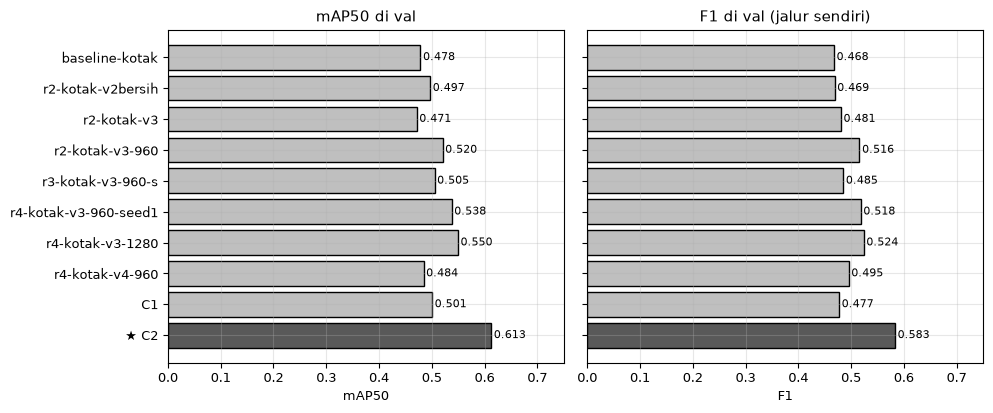

In [4]:
baris = []
for n in KOTAK:
    s = VS(n); j = s["jalur_sendiri"]; c = s["conf025"]
    ul = V[n].get("ultralytics", {}).get("box")
    baris.append([("★ " if n == FINAL_K else "") + n, f3(j["mAP50"]), f3(j["mAP50_95"]), f3(j["F1"]),
                  f3(ul["mAP50"]) if ul else "-", f3(ul["F1"]) if ul else "-",
                  tpfpfn(c["total"]), f"{c['fp_per_frame']:.2f}", rs(c["recall"]["dekat"])])
tabel(["Model (val)", "mAP50", "mAP50-95", "F1", "mAP50 (Ultra)", "F1 (Ultra)", "TP/FP/FN @0,25", "FP/frame", "Recall dekat"], baris, rata_kanan=[1, 2, 3, 4, 5, 7])

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
urut = KOTAK[::-1]
for ax, (kunci_m, judul) in zip(axs, (("mAP50", "mAP50 di val"), ("F1", "F1 di val (jalur sendiri)"))):
    nilai = [VS(n)["jalur_sendiri"][kunci_m] for n in urut]
    ax.barh(range(len(urut)), nilai, color=["0.35" if n == FINAL_K else "0.75" for n in urut], edgecolor="k", hatch=None)
    for y, v in enumerate(nilai):
        ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8)
    ax.set_yticks(range(len(urut))); ax.set_yticklabels([("★ " if n == FINAL_K else "") + n for n in urut])
    ax.set_xlabel(kunci_m); ax.set_title(judul); ax.set_xlim(0, 0.75)
fig.tight_layout(); plt.show()

In [5]:
RE_ENS = entri("ENS-ATURAN")
marg = float(re.search(r"\+ (0,\d+) DAN", RE_ENS).group(1).replace(",", "."))
gpu_b = float(re.search(r"GPU total <= (\d+) ms/frame", RE_ENS).group(1))
KP = baca_json(TF / "ens_kecepatan_protokol.json")
f1_r2 = VS(PEMBANDING)["jalur_sendiri"]["F1"]; f1_c2 = VS("C2")["jalur_sendiri"]["F1"]
tunggal = [n for n in KOTAK if n not in ("C1", "C2")]
terbaik_v = max(tunggal, key=lambda n: VS(n)["jalur_sendiri"]["F1"])
dk_r2 = VS(PEMBANDING)["conf025"]["recall"]["dekat"]["ditemukan"]; dk_c2 = VS("C2")["conf025"]["recall"]["dekat"]["ditemukan"]
display(Markdown(
    f"**Bacaan.** C2 (WBF empat model) punya mAP50 {f3(VS('C2')['jalur_sendiri']['mAP50'])} dan F1 {f3(f1_c2)} di val, tertinggi di antara semua model; model tunggal terbaik di val menurut F1 adalah `{terbaik_v}` "
    f"({f3(VS(terbaik_v)['jalur_sendiri']['F1'])}). C2 dipilih lewat aturan yang ditulis lebih dulu: F1 >= F1 acuan + {marg} (ambang {f3(f1_r2 + marg)}, lolos: {f1_c2 >= f1_r2 + marg}), "
    f"recall objek dekat tidak lebih rendah dari acuan ({dk_c2} vs {dk_r2}, lolos: {dk_c2 >= dk_r2}), dan GPU <= {gpu_b:.0f} ms/frame (diukur ulang dengan protokol: {KP['C2']['total_ms']:.1f} ms, lolos: {KP['lolos_60ms']}). "
    f"Kelemahannya: C2 menjalankan empat model per frame, dan karena C2 dipilih sebagai yang tertinggi dari banyak kandidat pada val kecil yang juga dipakai menyetel ambang, angka val-nya cenderung optimistis (bagian 6). "
    f"Baseline di val diukur pada label val v2 lewat jalur yang sama, bukan angka `results.csv` pelatihan (lihat Notebook 02)."))

**Bacaan.** C2 (WBF empat model) punya mAP50 0.613 dan F1 0.583 di val, tertinggi di antara semua model; model tunggal terbaik di val menurut F1 adalah `r4-kotak-v3-1280` (0.524). C2 dipilih lewat aturan yang ditulis lebih dulu: F1 >= F1 acuan + 0.034 (ambang 0.550, lolos: True), recall objek dekat tidak lebih rendah dari acuan (34 vs 33, lolos: True), dan GPU <= 60 ms/frame (diukur ulang dengan protokol: 49.5 ms, lolos: True). Kelemahannya: C2 menjalankan empat model per frame, dan karena C2 dipilih sebagai yang tertinggi dari banyak kandidat pada val kecil yang juga dipakai menyetel ambang, angka val-nya cenderung optimistis (bagian 6). Baseline di val diukur pada label val v2 lewat jalur yang sama, bukan angka `results.csv` pelatihan (lihat Notebook 02).

## 3. Pemilihan ambang per kelas (val)
Ambang conf tiap kelas ditentukan dari kurva F1 di val oleh aturan tertulis: ambang dengan F1 tertinggi pada grid, tetapi 0,25 jika kelas punya terlalu sedikit instance (angka berisik)
atau kurvanya datar, dan kelas "bahaya" diharuskan punya recall minimum. Parameter aturan dibaca dari `ambang_val_ens.json`; kurva dari `ambang_kurva_val_ens.csv`.
Garis tegak = ambang terpilih.

Parameter aturan,Nilai
grid ambang,0.05 sampai 0.8 (16 titik)
n val minimum agar F1 terbaik dipercaya,20
kurva dianggap datar jika selisih F1 <,0.02
kelas bahaya,"tangga, tepian, kendaraan"
recall minimum kelas bahaya,0.6
recall minimum khusus,tepian: 0.5


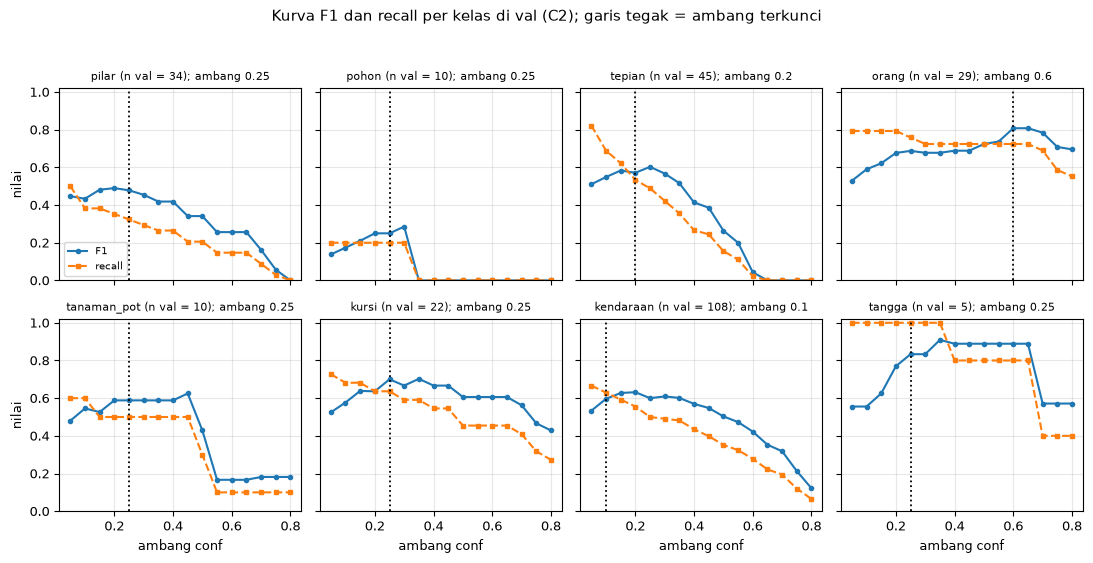

Kelas,n val,Ambang terpilih,Ambang F1 terbaik,F1 terbaik di val,Bahaya,Catatan aturan (dipotong)
pilar,34,0.25,0.2,0.490,tidak,"kurva datar (F1 terbaik 0.490 pada 0.2 vs 0.478 pada 0,25, selisih < 0.02): pakai 0,25"
pohon,10,0.25,0.3,0.286,tidak,"n val 10 < 20: pakai 0,25 (F1 terbaik di grid 0.286 pada 0.3)"
tepian,45,0.2,0.25,0.603,ya,"kurva datar (F1 terbaik 0.603 pada 0.25 vs 0.603 pada 0,25, selisih < 0.02): pakai 0,25; kelas bahaya: recall 0.489 pada"
orang,29,0.6,0.6,0.808,tidak,F1 terbaik 0.808 pada 0.6
tanaman_pot,10,0.25,0.45,0.625,tidak,"n val 10 < 20: pakai 0,25 (F1 terbaik di grid 0.625 pada 0.45)"
kursi,22,0.25,0.35,0.703,tidak,"kurva datar (F1 terbaik 0.703 pada 0.35 vs 0.700 pada 0,25, selisih < 0.02): pakai 0,25"
kendaraan,108,0.1,0.2,0.632,ya,"F1 terbaik 0.632 pada 0.2; kelas bahaya: recall 0.556 pada 0.2 < 0.6, diturunkan ke ambang tertinggi dengan recall >= 0."
tangga,5,0.25,0.35,0.909,ya,"n val 5 < 20: pakai 0,25 (F1 terbaik di grid 0.909 pada 0.35); kelas bahaya tetapi n < 20: aturan recall tidak diterapka"


In [6]:
ar = AMBANG["aturan"]
tabel(["Parameter aturan", "Nilai"], [
    ["grid ambang", f"{ar['grid'][0]} sampai {ar['grid'][-1]} ({len(ar['grid'])} titik)"],
    ["n val minimum agar F1 terbaik dipercaya", ar["n_min"]],
    ["kurva dianggap datar jika selisih F1 <", ar["datar"]],
    ["kelas bahaya", ", ".join(ar["kelas_bahaya"])],
    ["recall minimum kelas bahaya", ar["recall_min_bahaya"]],
    ["recall minimum khusus", ", ".join(f"{k}: {v}" for k, v in ar["recall_min_khusus"].items())],
])
kurva = baca_csv(TF / "ambang_kurva_val_ens.csv")
fig, axs = plt.subplots(2, 4, figsize=(11, 5.6), sharex=True, sharey=True)
for ax, k in zip(axs.ravel(), NAMES):
    r = [x for x in kurva if x["kelas"] == k]
    a = [float(x["ambang"]) for x in r]
    ax.plot(a, [float(x["F1"]) for x in r], "-o", ms=3, label="F1")
    ax.plot(a, [float(x["R"]) for x in r], "--s", ms=3, label="recall")
    ax.axvline(CK[k], color="k", ls=":", lw=1.3)
    ax.set_title(f"{k} (n val = {r[0]['n_val']}); ambang {CK[k]}", fontsize=8)
    ax.set_ylim(0, 1.02)
for ax in axs[1]:
    ax.set_xlabel("ambang conf")
for ax in axs[:, 0]:
    ax.set_ylabel("nilai")
axs[0, 0].legend(fontsize=7, loc="lower left")
fig.suptitle("Kurva F1 dan recall per kelas di val (C2); garis tegak = ambang terkunci", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

baris = []
for k in NAMES:
    r = AMBANG["rinci"][k]
    baris.append([k, r["n_val"], r["ambang"], r["ambang_F1_terbaik"], f3(r["F1_terbaik"]), "ya" if r["bahaya"] else "tidak", r["catatan"][:120]])
tabel(["Kelas", "n val", "Ambang terpilih", "Ambang F1 terbaik", "F1 terbaik di val", "Bahaya", "Catatan aturan (dipotong)"], baris, rata_kanan=[1, 2, 3, 4])

In [7]:
rin = AMBANG["rinci"]
kecil = [k for k in NAMES if rin[k]["n_val"] < ar["n_min"]]
beda = [k for k in NAMES if abs(rin[k]["ambang"] - rin[k]["ambang_F1_terbaik"]) > 1e-9]
bukan_default = [k for k in NAMES if abs(CK[k] - 0.25) > 1e-9]
ket_kecil = ", ".join(k + " (" + str(rin[k]["n_val"]) + ")" for k in kecil)
ket_bd = ", ".join(k + " " + str(CK[k]) for k in bukan_default)
display(Markdown(
    f"**Bacaan.** {len(kecil)} dari {len(NAMES)} kelas punya n val < {ar['n_min']} ({ket_kecil}) sehingga ambangnya dikembalikan ke 0,25 walau kurva F1 menunjuk ambang lain; "
    f"kurva untuk kelas-kelas itu terlalu berisik untuk dipercaya. Hanya {len(bukan_default)} kelas yang ambangnya bukan 0,25 ({ket_bd}); sisanya tetap 0,25. "
    f"Ambang terpilih berbeda dari ambang F1-terbaik pada {len(beda)} kelas, karena aturan n minimum, aturan 'kurva datar', dan syarat recall kelas bahaya. "
    "Kelemahan: seluruh ambang disetel di val yang kecil dan dipakai ulang di lokasi baru; bila distribusi skor berubah di lokasi baru (seperti terlihat pada bagian 5 dan 6), ambang ini tidak lagi optimal."))

**Bacaan.** 3 dari 8 kelas punya n val < 20 (pohon (10), tanaman_pot (10), tangga (5)) sehingga ambangnya dikembalikan ke 0,25 walau kurva F1 menunjuk ambang lain; kurva untuk kelas-kelas itu terlalu berisik untuk dipercaya. Hanya 3 kelas yang ambangnya bukan 0,25 (tepian 0.2, orang 0.6, kendaraan 0.1); sisanya tetap 0,25. Ambang terpilih berbeda dari ambang F1-terbaik pada 7 kelas, karena aturan n minimum, aturan 'kurva datar', dan syarat recall kelas bahaya. Kelemahan: seluruh ambang disetel di val yang kecil dan dipakai ulang di lokasi baru; bila distribusi skor berubah di lokasi baru (seperti terlihat pada bagian 5 dan 6), ambang ini tidak lagi optimal.

## 4. Matriks konfusi di val
Gambar di bawah adalah matriks konfusi Ultralytics yang sudah tersimpan untuk model tunggal `r2-kotak-v3-960` pada **val v2** (ternormalisasi per kelas sebenarnya; dihitung pada conf rendah 0,001, sehingga kolom/baris *background* besar).
Catatan penamaan: folder `runs/test-final/r2-kotak-v3-960-val/` **bukan** val, melainkan hasil **test** (nama folder berakhiran `-val` karena fungsi yang dipakai; lihat `docs/hasil-test-final.md` bagian 11),
jadi gambar val diambil dari `runs/ronde2/r2-kotak-v3-960/`.

Ukuran asli: (3000, 2250) -> ditampilkan lebar <= 1000 px


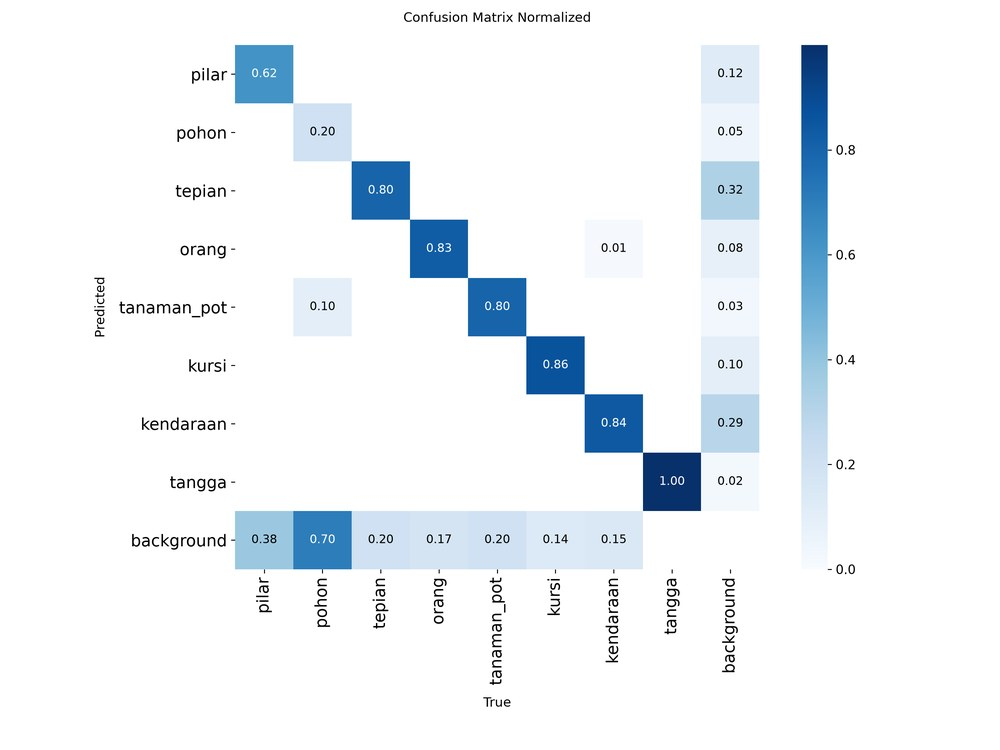

In [8]:
p = ROOT / "runs/ronde2/r2-kotak-v3-960/confusion_matrix_normalized.png"
cek_putih(p)
im = Image.open(p)
print("Ukuran asli:", im.size, "-> ditampilkan lebar <= 1000 px")
tampil_jpeg(im, lebar=1000, mutu=88)

Val, C2, ambang terkunci: dari matriks TP/FP/FN = 150/76/113; tercatat di t1_val/C2.json = 150/76/113 -> SAMA


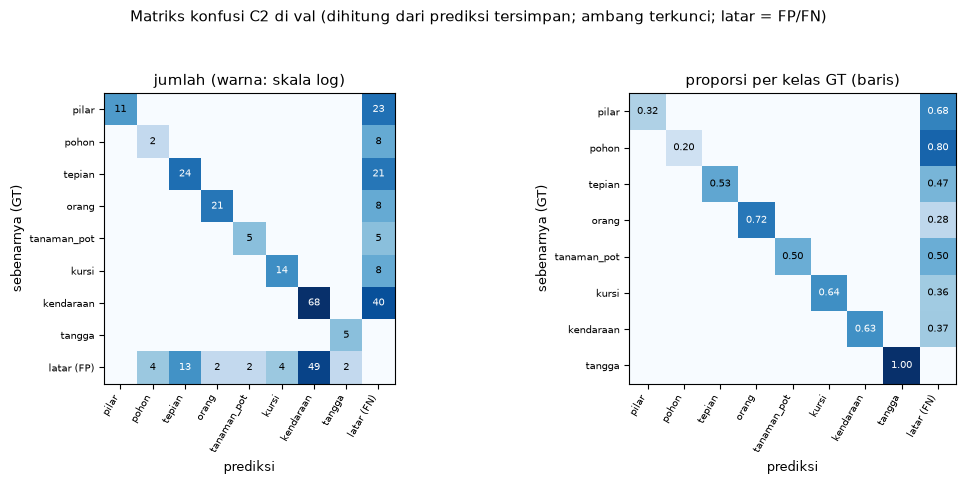

In [9]:
def bangun_cm(names, imgs, lab_dir, pred, amb):
    # matriks [GT][prediksi] 9x9: diagonal = TP; kolom latar = FN per kelas GT; baris latar = FP per kelas prediksi.
    # Pencocokan SAMA dengan tools/test_t1.py (tf.hitung -> eb.cocokkan_kotak, IoU >= 0,5, kelas sama).
    n = len(names)
    M = np.zeros((n + 1, n + 1), dtype=int)
    st, fps, gts, per = tf.hitung(names, imgs, lab_dir, pred, amb)
    for k, v in st.items():
        M[k, k] = v["tp"]; M[k, n] = v["fn"]; M[n, k] = v["fp"]
    tukar = collections.Counter((x["tertukar_dengan"], names[x["kelas"]]) for x in fps if x["tertukar_dengan"])
    tot = dict(tp=int(np.trace(M[:n, :n])), fp=int(M[n, :n].sum()), fn=int(M[:n, n].sum()))
    return M, tot, tukar

def gambar_cm(M, labels, judul):
    n = len(labels)
    xl = labels + ["latar (FN)"]; yl = labels + ["latar (FP)"]
    norm = M[:n].astype(float) / np.maximum(M[:n].sum(axis=1, keepdims=True), 1)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
    ax = axs[0]
    ax.imshow(np.log1p(M), cmap="Blues"); ax.grid(False)
    for i in range(n + 1):
        for j in range(n + 1):
            if M[i, j]:
                ax.text(j, i, str(M[i, j]), ha="center", va="center", fontsize=7, color="white" if np.log1p(M[i, j]) > 0.6 * np.log1p(M.max()) else "black")
    ax.set_xticks(range(n + 1)); ax.set_xticklabels(xl, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(n + 1)); ax.set_yticklabels(yl, fontsize=7)
    ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya (GT)"); ax.set_title("jumlah (warna: skala log)")
    ax = axs[1]
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(n):
        if M[i].sum() == 0:
            ax.text(n / 2, i, "tanpa GT di set ini", ha="center", va="center", fontsize=7, color="0.4")
            continue
        for j in range(n + 1):
            if norm[i, j] >= 0.005:
                ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if norm[i, j] > 0.6 else "black")
    ax.set_xticks(range(n + 1)); ax.set_xticklabels(xl, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya (GT)"); ax.set_title("proporsi per kelas GT (baris)")
    fig.suptitle(judul, y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

PRED_V = pickle.loads((TF / "t1_val/pred_C2.pkl").read_bytes())
M_V, tot_v, tukar_v = bangun_cm(NAMA_K, IMGS_VAL, LAB_VAL, PRED_V["c005"], AMB_ID)
cat_v = VS("C2")["ambang_terkunci"]["total"]
print(f"Val, C2, ambang terkunci: dari matriks TP/FP/FN = {tot_v['tp']}/{tot_v['fp']}/{tot_v['fn']}; tercatat di t1_val/C2.json = {cat_v['tp']}/{cat_v['fp']}/{cat_v['fn']} -> {'SAMA' if (tot_v['tp'], tot_v['fp'], tot_v['fn']) == (cat_v['tp'], cat_v['fp'], cat_v['fn']) else 'BEDA'}")
gambar_cm(M_V, NAMES, "Matriks konfusi C2 di val (dihitung dari prediksi tersimpan; ambang terkunci; latar = FP/FN)")

In [10]:
n_ = len(NAMES)
fn_k = {NAMES[i]: int(M_V[i, n_]) for i in range(n_)}
fp_k = {NAMES[i]: int(M_V[n_, i]) for i in range(n_)}
gt_k = {NAMES[i]: int(M_V[i].sum()) for i in range(n_)}
rec = {k: (M_V[i, i] / gt_k[k] if gt_k[k] else None) for i, k in enumerate(NAMES)}
rendah = sorted([k for k in NAMES if rec[k] is not None and gt_k[k] >= ar["n_min"]], key=lambda k: rec[k])[:2]
fp_top = max(fp_k, key=fp_k.get)
antar = sum(tukar_v.values())
ket_tv = ", ".join(a + " diprediksi " + b + ": " + str(c) for (a, b), c in tukar_v.items()) or "tidak ada"
display(Markdown(
    f"**Bacaan.** Dihitung ulang dari prediksi C2 yang tersimpan pada ambang terkunci (angka TP/FP/FN cocok dengan yang tercatat): {tot_v['fn']} objek terlewat (FN) dan {tot_v['fp']} kotak tanpa GT (FP). "
    f"Dari {tot_v['fp']} kotak salah itu hanya {antar} yang menimpa GT kelas lain ({ket_tv}); selebihnya kotak di latar. "
    f"Di antara kelas dengan n >= {ar['n_min']}, recall terendah ada pada {rendah[0]} ({rec[rendah[0]]:.2f}) dan {rendah[1]} ({rec[rendah[1]]:.2f}); kotak salah terbanyak adalah kelas {fp_top} ({fp_k[fp_top]}). "
    "Kelemahan: matriks ini memakai ambang yang disetel di val yang sama, dan gambar Ultralytics di atas adalah model tunggal pada conf 0,001, jadi keduanya tidak bisa dibandingkan angka demi angka."))

**Bacaan.** Dihitung ulang dari prediksi C2 yang tersimpan pada ambang terkunci (angka TP/FP/FN cocok dengan yang tercatat): 113 objek terlewat (FN) dan 76 kotak tanpa GT (FP). Dari 76 kotak salah itu hanya 2 yang menimpa GT kelas lain (pilar diprediksi kendaraan: 2); selebihnya kotak di latar. Di antara kelas dengan n >= 20, recall terendah ada pada pilar (0.32) dan tepian (0.53); kotak salah terbanyak adalah kelas kendaraan (49). Kelemahan: matriks ini memakai ambang yang disetel di val yang sama, dan gambar Ultralytics di atas adalah model tunggal pada conf 0,001, jadi keduanya tidak bisa dibandingkan angka demi angka.

## 5. Hasil test
Test set: 91 frame di tiga lokasi yang tidak pernah ada di data latih maupun val (lantai 11 dalam gedung dan taman-ubm luar gedung), dua sudut pandang (dada dan mata). Semua angka dibaca dari `t1/*.json`; test dievaluasi satu kali per model.

### 5.1 Semua model kotak
Mulai dari tabel utama: mAP50, mAP50-95 dan F1 dari jalur sendiri (satu jalur untuk semua model), lalu metrik berambang pada conf 0,25 seragam.

In [11]:
baris = []
for n in KOTAK:
    s = TS(n); j = s["jalur_sendiri"]; c = s["conf025"]; fr = c["frame"]
    baris.append([("★ " if n == FINAL_K else "") + n, f3(j["mAP50"]), f3(j["mAP50_95"]), f3(j["F1"]), tpfpfn(c["total"]), f"{c['fp_per_frame']:.2f}",
                  rs(c["recall"]["dekat"]), rs(c["recall"]["jauh"]), f"{fr['TP']}/{fr['FP']}/{fr['FN']}/{fr['TN']}"])
tabel(["Model (test)", "mAP50", "mAP50-95", "F1", "TP/FP/FN @0,25", "FP/frame", "Recall dekat", "Recall sisanya", "Frame TP/FP/FN/TN @0,25"], baris, rata_kanan=[1, 2, 3, 5])
n_t = TS("C2")["conf025"]["total"]["tp"] + TS("C2")["conf025"]["total"]["fn"]
urut_m = sorted(KOTAK, key=lambda n: -TS(n)["jalur_sendiri"]["mAP50"])
urut_f = sorted(KOTAK, key=lambda n: -TS(n)["jalur_sendiri"]["F1"])
sel_c2_1280 = TS("C2")["jalur_sendiri"]["mAP50"] - TS("r4-kotak-v3-1280")["jalur_sendiri"]["mAP50"]
display(Markdown(
    f"**Bacaan.** Di test ({TS('C2')['n_frame']} frame, {n_t} kotak), mAP50 tertinggi adalah `{urut_m[0]}` ({f3(TS(urut_m[0])['jalur_sendiri']['mAP50'])}) disusul `{urut_m[1]}` ({f3(TS(urut_m[1])['jalur_sendiri']['mAP50'])}); "
    f"yang terendah `{urut_m[-1]}` ({f3(TS(urut_m[-1])['jalur_sendiri']['mAP50'])}). F1 tertinggi `{urut_f[0]}` ({f3(TS(urut_f[0])['jalur_sendiri']['F1'])}). "
    f"Jarak C2 ke model tunggal terbaik kedua (`r4-kotak-v3-1280`) hanya {sel_c2_1280:+.3f} mAP50, dan model tunggal itu lebih unggul di F1 ({f3(TS('r4-kotak-v3-1280')['jalur_sendiri']['F1'])} vs {f3(TS('C2')['jalur_sendiri']['F1'])}); "
    "selisih sekecil itu pada 91 frame tidak bisa dibedakan dari derau (margin derau seed di val sudah 0,034 F1; di test derau tidak lebih kecil). "
    f"Yang cukup jelas hanya: baseline paling rendah, dan semua model ronde 2 ke atas di atasnya. `r2-kotak-v3-960` yang unggul di val tidak lebih baik dari model 640 px di test ({f3(TS(PEMBANDING)['jalur_sendiri']['mAP50'])} vs {f3(TS('r2-kotak-v3')['jalur_sendiri']['mAP50'])}). "
    "TTA (C1) menambah kotak salah tanpa menaikkan mAP."))

Model (test),mAP50,mAP50-95,F1,"TP/FP/FN @0,25",FP/frame,Recall dekat,Recall sisanya,"Frame TP/FP/FN/TN @0,25"
baseline-kotak,0.209,0.120,0.239,66/145/171,1.59,14/68 (0.21),52/169 (0.31),22/2/21/46
r2-kotak-v2bersih,0.244,0.153,0.280,80/119/157,1.31,24/68 (0.35),56/169 (0.33),27/3/16/45
r2-kotak-v3,0.237,0.131,0.278,74/120/163,1.32,24/68 (0.35),50/169 (0.30),28/1/15/47
r2-kotak-v3-960,0.231,0.125,0.294,71/123/166,1.35,18/68 (0.26),53/169 (0.31),22/1/21/47
r3-kotak-v3-960-s,0.243,0.138,0.279,81/153/156,1.68,21/68 (0.31),60/169 (0.36),27/1/16/47
r4-kotak-v3-960-seed1,0.280,0.144,0.273,83/150/154,1.65,22/68 (0.32),61/169 (0.36),28/2/15/46
r4-kotak-v3-1280,0.292,0.160,0.315,95/136/142,1.49,20/68 (0.29),75/169 (0.44),24/2/19/46
r4-kotak-v4-960,0.237,0.140,0.275,66/114/171,1.25,19/68 (0.28),47/169 (0.28),24/1/19/47
C1,0.236,0.135,0.279,84/181/153,1.99,23/68 (0.34),61/169 (0.36),32/2/11/46
★ C2,0.305,0.172,0.308,80/111/157,1.22,22/68 (0.32),58/169 (0.34),27/0/16/48


**Bacaan.** Di test (91 frame, 237 kotak), mAP50 tertinggi adalah `C2` (0.305) disusul `r4-kotak-v3-1280` (0.292); yang terendah `baseline-kotak` (0.209). F1 tertinggi `r4-kotak-v3-1280` (0.315). Jarak C2 ke model tunggal terbaik kedua (`r4-kotak-v3-1280`) hanya +0.013 mAP50, dan model tunggal itu lebih unggul di F1 (0.315 vs 0.308); selisih sekecil itu pada 91 frame tidak bisa dibedakan dari derau (margin derau seed di val sudah 0,034 F1; di test derau tidak lebih kecil). Yang cukup jelas hanya: baseline paling rendah, dan semua model ronde 2 ke atas di atasnya. `r2-kotak-v3-960` yang unggul di val tidak lebih baik dari model 640 px di test (0.231 vs 0.237). TTA (C1) menambah kotak salah tanpa menaikkan mAP.

### 5.2 C2 pada pengaturan app, per subset
Pengaturan app = ambang per kelas terkunci dan prediksi conf anggota 0,05. Subset: semua frame, dua lokasi (lantai 11, taman-ubm), dan dua sudut pandang (dada, mata).
Pembanding: `r2-kotak-v3-960` (final sebelum ensemble) pada ambangnya sendiri.

In [12]:
def baris_subset(model, sn):
    s = TS(model, sn); a = s["ambang_terkunci"]; fr = a["frame"]
    return [model, f"{sn} ({s['n_frame']})", tpfpfn(a["total"]), f3(a["P_mikro"]), f3(a["R_mikro"]), f"{a['fp_per_frame']:.2f}", rs(a["recall"]["dekat"]),
            f"{fr['TP']}/{fr['FP']}/{fr['FN']}/{fr['TN']}", f3(fr["precision"]), f3(fr["recall"])]
SUB = ["semua", "lantai11", "taman-ubm", "dada", "mata"]
baris = [baris_subset("C2", sn) for sn in SUB] + [baris_subset(PEMBANDING, "semua")]
tabel(["Model", "Subset (frame)", "TP/FP/FN", "Precision", "Recall", "FP/frame", "Recall dekat", "Frame TP/FP/FN/TN", "Frame P", "Frame R"], baris, rata_kanan=[3, 4, 5, 8, 9])
a_all = TS("C2")["ambang_terkunci"]
lt, tm = TS("C2", "lantai11")["ambang_terkunci"], TS("C2", "taman-ubm")["ambang_terkunci"]
dd, mt_ = TS("C2", "dada")["ambang_terkunci"], TS("C2", "mata")["ambang_terkunci"]
r2a = TS(PEMBANDING)["ambang_terkunci"]
display(Markdown(
    f"**Bacaan.** Pada ambang terkunci C2 menemukan {a_all['total']['tp']} dari {a_all['total']['tp'] + a_all['total']['fn']} objek dengan {a_all['total']['fp']} kotak salah ({a_all['fp_per_frame']:.2f} per frame). "
    f"Perbedaan lokasi mencolok: lantai 11 hanya {lt['fp_per_frame']:.2f} kotak salah per frame (precision {f3(lt['P_mikro'])}) tetapi recall {f3(lt['R_mikro'])}; taman-ubm {tm['fp_per_frame']:.2f} per frame (precision {f3(tm['P_mikro'])}, recall {f3(tm['R_mikro'])}). "
    f"Dada vs mata hampir sama ({dd['fp_per_frame']:.2f} vs {mt_['fp_per_frame']:.2f} kotak salah per frame; recall {f3(dd['R_mikro'])} vs {f3(mt_['R_mikro'])}). "
    f"Dibanding `{PEMBANDING}` pada ambangnya sendiri, C2 lebih baik pada TP ({a_all['total']['tp']} vs {r2a['total']['tp']}), FP ({a_all['total']['fp']} vs {r2a['total']['fp']}), recall dekat ({a_all['recall']['dekat']['ditemukan']} vs {r2a['recall']['dekat']['ditemukan']}) dan recall frame ({f3(a_all['frame']['recall'])} vs {f3(r2a['frame']['recall'])}). "
    "Kelemahan: tiap subset hanya beberapa puluh frame dari satu hari rekaman, jadi perbedaan kecil antar subset (dada vs mata) tidak berarti."))

Model,Subset (frame),TP/FP/FN,Precision,Recall,FP/frame,Recall dekat,Frame TP/FP/FN/TN,Frame P,Frame R
C2,semua (91),77/103/160,0.428,0.325,1.13,21/68 (0.31),29/0/14/48,1.000,0.674
C2,lantai11 (45),37/6/47,0.860,0.440,0.13,12/36 (0.33),12/0/5/28,1.000,0.706
C2,taman-ubm (46),40/97/113,0.292,0.261,2.11,9/32 (0.28),17/0/9/20,1.000,0.654
C2,dada (46),38/45/81,0.458,0.319,0.98,11/34 (0.32),14/0/7/25,1.000,0.667
C2,mata (45),39/58/79,0.402,0.331,1.29,10/34 (0.29),15/0/7/23,1.000,0.682
r2-kotak-v3-960,semua (91),67/124/170,0.351,0.283,1.36,16/68 (0.24),21/1/22/47,0.955,0.488


**Bacaan.** Pada ambang terkunci C2 menemukan 77 dari 237 objek dengan 103 kotak salah (1.13 per frame). Perbedaan lokasi mencolok: lantai 11 hanya 0.13 kotak salah per frame (precision 0.860) tetapi recall 0.440; taman-ubm 2.11 per frame (precision 0.292, recall 0.261). Dada vs mata hampir sama (0.98 vs 1.29 kotak salah per frame; recall 0.319 vs 0.331). Dibanding `r2-kotak-v3-960` pada ambangnya sendiri, C2 lebih baik pada TP (77 vs 67), FP (103 vs 124), recall dekat (21 vs 16) dan recall frame (0.674 vs 0.488). Kelemahan: tiap subset hanya beberapa puluh frame dari satu hari rekaman, jadi perbedaan kecil antar subset (dada vs mata) tidak berarti.

### 5.3 Per kelas (C2, ambang terkunci)
AP50 dari jalur sendiri; recall dekat dari definisi y2. Kelas dengan n < 20 ditandai ★ (angka sangat berisik). `kendaraan` dan `tangga` tidak punya instance di test.

Kelas,Ambang,n test,TP,FP,FN,P,R,Dekat,AP50 test,AP50 val,n val
pilar,0.25,38,15,9,23,0.62,0.39,5/7 (0.71),0.463,0.488,34
pohon ★,0.25,3,2,18,1,0.10,0.67,0/0,0.223,0.126,10
tepian,0.2,51,11,20,40,0.35,0.22,0/22 (0.00),0.147,0.630,45
orang,0.6,32,13,5,19,0.72,0.41,1/3 (0.33),0.567,0.787,29
tanaman_pot,0.25,99,36,48,63,0.43,0.36,15/25 (0.60),0.405,0.564,10
kursi ★,0.25,14,0,1,14,0.00,0.00,0/11 (0.00),0.028,0.690,22
kendaraan,0.1,0,0,1,0,0.00,-,0/0,-,0.621,108
tangga,0.25,0,0,1,0,0.00,-,0/0,-,0.995,5


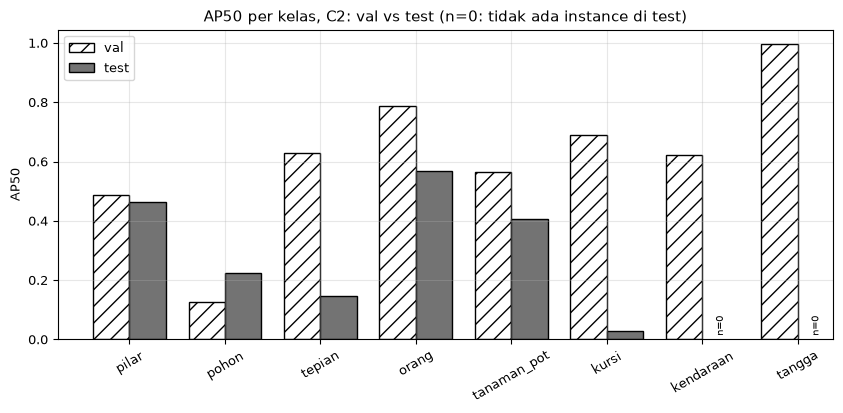

**Bacaan.** Penurunan AP50 terbesar val ke test: kursi (-0.66), tepian (-0.48), orang (-0.22). Kasus paling berbahaya untuk pengguna adalah `tepian` dekat: 0 dari 22 ditemukan, dan `kursi` (14 instance): 0 ditemukan. Relatif bertahan: pilar (AP50 test 0.46 vs val 0.49); orang masih presisi (precision 0.72) walau AP50-nya turun. Kotak salah terbanyak: tanaman_pot (48) dan pohon (18 untuk 3 pohon asli). Kelemahan: pohon, kursi hanya belasan instance atau kurang sehingga AP-nya sangat berisik; kendaraan dan tangga tidak terukur di lokasi baru sama sekali.

In [13]:
kk_t = TS("C2")["jalur_sendiri"]["kelas"]; kk_v = VS("C2")["jalur_sendiri"]["kelas"]
pk = a_all["per_kelas"]; rk = a_all["recall"]["per_kelas"]
baris = []
for k in NAMES:
    n_test = pk[k]["n"]
    baris.append([k + (" ★" if 0 < n_test < ar["n_min"] else ""), CK[k], n_test, pk[k]["tp"], pk[k]["fp"], pk[k]["fn"], f3(pk[k]["P"], 2), f3(pk[k]["R"], 2),
                  rs(rk[k]["dekat"]), f3(kk_t[k]["AP50"]) if k in kk_t and n_test else "-", f3(kk_v[k]["AP50"]) if k in kk_v else "-", kk_v[k]["n"] if k in kk_v else "-"])
tabel(["Kelas", "Ambang", "n test", "TP", "FP", "FN", "P", "R", "Dekat", "AP50 test", "AP50 val", "n val"], baris, rata_kanan=[1, 2, 3, 4, 5, 6, 7, 9, 10, 11])

ada = [k for k in NAMES if pk[k]["n"] > 0]
turun = sorted([(kk_v[k]["AP50"] - kk_t[k]["AP50"], k) for k in ada if k in kk_v and k in kk_t and kk_t[k].get("AP50") is not None and not np.isnan(kk_t[k]["AP50"])], reverse=True)
txt_turun = ", ".join(k + " (-" + f"{d:.2f}" + ")" for d, k in turun[:3])
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(NAMES)); w = 0.38
v_ap = [kk_v[k]["AP50"] if k in kk_v else np.nan for k in NAMES]
t_ap = [kk_t[k]["AP50"] if (k in kk_t and pk[k]["n"] > 0) else np.nan for k in NAMES]
ax.bar(x - w / 2, v_ap, w, color="white", edgecolor="k", hatch="//", label="val")
ax.bar(x + w / 2, t_ap, w, color="0.45", edgecolor="k", label="test")
for i, k in enumerate(NAMES):
    if pk[k]["n"] == 0:
        ax.text(i + w / 2, 0.02, "n=0", ha="center", fontsize=7, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(NAMES, rotation=30); ax.set_ylabel("AP50"); ax.set_title("AP50 per kelas, C2: val vs test (n=0: tidak ada instance di test)")
ax.legend(); fig.tight_layout(); plt.show()
kursi_r = rk["kursi"]["dekat"]; tep = rk["tepian"]["dekat"]
display(Markdown(
    f"**Bacaan.** Penurunan AP50 terbesar val ke test: {txt_turun}. "
    f"Kasus paling berbahaya untuk pengguna adalah `tepian` dekat: {tep['ditemukan']} dari {tep['gt']} ditemukan, dan `kursi` ({pk['kursi']['n']} instance): {pk['kursi']['tp']} ditemukan. "
    f"Relatif bertahan: pilar (AP50 test {f3(kk_t['pilar']['AP50'], 2)} vs val {f3(kk_v['pilar']['AP50'], 2)}); orang masih presisi (precision {pk['orang']['P']:.2f}) walau AP50-nya turun. "
    f"Kotak salah terbanyak: tanaman_pot ({pk['tanaman_pot']['fp']}) dan pohon ({pk['pohon']['fp']} untuk {pk['pohon']['n']} pohon asli). "
    "Kelemahan: pohon, kursi hanya belasan instance atau kurang sehingga AP-nya sangat berisik; kendaraan dan tangga tidak terukur di lokasi baru sama sekali."))

### 5.4 Peringatan tingkat frame dan objek dekat
Untuk aplikasi, "ada rintangan dekat di tengah" lebih penting daripada nama benda. Frame-level: dihitung dari GT dan prediksi dengan aturan yang sama (zona dekat + pita tengah).
Tabel kiri: semua model pada conf 0,25 seragam; baris terakhir: pengaturan app C2 (ambang terkunci). Recall per ukuran objek (px skala 640) membaca apakah masalahnya hanya objek kecil.

In [14]:
baris = []
for n in KOTAK:
    fr = TS(n)["conf025"]["frame"]
    baris.append([("★ " if n == FINAL_K else "") + n, f"{fr['TP']}/{fr['FP']}/{fr['FN']}/{fr['TN']}", f3(fr["precision"], 2), f3(fr["recall"], 2)])
fk = a_all["frame"]
baris.append(["C2, pengaturan app (ambang terkunci)", f"{fk['TP']}/{fk['FP']}/{fk['FN']}/{fk['TN']}", f3(fk["precision"], 2), f3(fk["recall"], 2)])
tabel(["Model (test)", "Frame TP/FP/FN/TN", "Precision", "Recall"], baris, rata_kanan=[2, 3])

pu = a_all["recall"]["per_ukuran"]
print("Recall per ukuran objek, C2 ambang terkunci (px pada skala 640), ditemukan/GT:")
tabel(["Ukuran"] + list(pu.keys()), [["C2 test"] + [rs(v) for v in pu.values()]] + [["C2 val"] + [rs(v) for v in VS("C2")["ambang_terkunci"]["recall"]["per_ukuran"].values()]])
negatif = fk["FP"] + fk["TN"]
PF = [TS(n)["conf025"]["frame"]["precision"] for n in KOTAK if TS(n)["conf025"]["frame"]["precision"] is not None]
val_dekat = VS("C2")["ambang_terkunci"]["recall"]["dekat"]
display(Markdown(
    f"**Bacaan.** Pada pengaturan app C2 salah memperingatkan di {fk['FP']} dari {negatif} frame tanpa rintangan dekat, tetapi melewatkan {fk['FN']} dari {fk['TP'] + fk['FN']} frame yang berbahaya (recall {fk['recall']:.3f}). "
    f"Peringatan tingkat frame jauh lebih bisa dipercaya daripada kotak per objek: presisi frame {f3(min(PF), 2)}-{f3(max(PF), 2)} untuk semua model pada conf 0,25 (presisi kotak per objek: {f3(min(TS(n)['conf025']['total']['tp'] / (TS(n)['conf025']['total']['tp'] + TS(n)['conf025']['total']['fp']) for n in KOTAK), 2)}-{f3(max(TS(n)['conf025']['total']['tp'] / (TS(n)['conf025']['total']['tp'] + TS(n)['conf025']['total']['fp']) for n in KOTAK), 2)}). "
    f"Recall objek dekat C2 hanya {rs(a_all['recall']['dekat'])} di test (val: {rs(val_dekat)}). "
    f"Objek besar (>= 128 px) pun hanya ditemukan {pu['>=128']['recall']:.2f}, jadi kegagalan bukan hanya soal objek kecil. "
    "Kelemahan: definisi 'dekat' adalah heuristik posisi (tepi bawah kotak), bukan jarak nyata, dan hanya 43 frame positif yang menjadi dasar recall frame."))

Model (test),Frame TP/FP/FN/TN,Precision,Recall
baseline-kotak,22/2/21/46,0.92,0.51
r2-kotak-v2bersih,27/3/16/45,0.90,0.63
r2-kotak-v3,28/1/15/47,0.97,0.65
r2-kotak-v3-960,22/1/21/47,0.96,0.51
r3-kotak-v3-960-s,27/1/16/47,0.96,0.63
r4-kotak-v3-960-seed1,28/2/15/46,0.93,0.65
r4-kotak-v3-1280,24/2/19/46,0.92,0.56
r4-kotak-v4-960,24/1/19/47,0.96,0.56
C1,32/2/11/46,0.94,0.74
★ C2,27/0/16/48,1.00,0.63


Recall per ukuran objek, C2 ambang terkunci (px pada skala 640), ditemukan/GT:


Ukuran,<32,32-64,64-128,>=128
C2 test,7/23 (0.30),17/57 (0.30),20/69 (0.29),33/88 (0.38)
C2 val,5/24 (0.21),52/102 (0.51),69/104 (0.66),24/33 (0.73)


**Bacaan.** Pada pengaturan app C2 salah memperingatkan di 0 dari 48 frame tanpa rintangan dekat, tetapi melewatkan 14 dari 43 frame yang berbahaya (recall 0.674). Peringatan tingkat frame jauh lebih bisa dipercaya daripada kotak per objek: presisi frame 0.90-1.00 untuk semua model pada conf 0,25 (presisi kotak per objek: 0.31-0.42). Recall objek dekat C2 hanya 21/68 (0.31) di test (val: 38/72 (0.53)). Objek besar (>= 128 px) pun hanya ditemukan 0.38, jadi kegagalan bukan hanya soal objek kecil. Kelemahan: definisi 'dekat' adalah heuristik posisi (tepi bawah kotak), bukan jarak nyata, dan hanya 43 frame positif yang menjadi dasar recall frame.

### 5.5 Segmentasi
Tiga model segmentasi (baseline, final `r2-seg-v3`, `r4-seg-v4`). Mask mAP dari tabel Ultralytics; IoU piksel = irisan/gabungan piksel semua frame untuk satu kelas (conf 0,25). `tangga` tidak ada di test.

In [15]:
baris = []
for n in SEG:
    m_t = T[n]["ultralytics"]["mask"]; m_v = V[n]["ultralytics"]["mask"]
    it, iv = TS(n)["iou_piksel_per_kelas"], VS(n)["iou_piksel_per_kelas"]
    baris.append([("★ " if n == FINAL_S else "") + n, f3(m_t["mAP50"]), f3(m_t["mAP50_95"]), f3(m_t["P"]), f3(m_t["R"]), f3(it["jalur_jalan"]), f3(it["jalan_kendaraan"]),
                  f3(m_v["mAP50"]), f3(iv["jalur_jalan"])])
tabel(["Model", "mask mAP50 (test)", "mask mAP50-95", "P", "R", "IoU jalur_jalan (test)", "IoU jalan_kendaraan (test)", "mask mAP50 (val)", "IoU jalur_jalan (val)"], baris, rata_kanan=[1, 2, 3, 4, 5, 6, 7, 8])

print("IoU piksel per subset, jalur_jalan / jalan_kendaraan (test):")
tabel(["Model"] + SUB, [[n] + [f"{f3(TS(n, s)['iou_piksel_per_kelas']['jalur_jalan'], 2)} / {f3(TS(n, s)['iou_piksel_per_kelas']['jalan_kendaraan'], 2)}" for s in SUB] for n in SEG])
kl = {k["nama"]: k for k in T[FINAL_S]["ultralytics"]["mask"]["kelas"]}
iou_f = TS(FINAL_S)["iou_piksel_per_kelas"]; iou_b = TS("baseline-seg")["iou_piksel_per_kelas"]
display(Markdown(
    f"**Bacaan.** `jalur_jalan` ({kl['jalur_jalan']['n_instance']} polygon) tetap baik di lokasi baru: IoU piksel {f3(iou_f['jalur_jalan'], 2)} untuk model final dan {f3(iou_b['jalur_jalan'], 2)} untuk baseline; ini bagian yang paling bisa diandalkan. "
    f"`jalan_kendaraan` ({kl['jalan_kendaraan']['n_instance']} polygon, hanya di taman) gagal pada ketiga model (IoU <= {max(TS(n)['iou_piksel_per_kelas']['jalan_kendaraan'] for n in SEG):.2f}), sehingga mask mAP rata-rata rendah. "
    f"Model final **tidak lebih baik dari baseline** di test: mask mAP50 hanya {T[FINAL_S]['ultralytics']['mask']['mAP50'] - T['baseline-seg']['ultralytics']['mask']['mAP50']:+.3f} ({f3(T[FINAL_S]['ultralytics']['mask']['mAP50'])} vs {f3(T['baseline-seg']['ultralytics']['mask']['mAP50'])}, di bawah derau) dan IoU jalur_jalan lebih rendah ({f3(iou_f['jalur_jalan'], 2)} vs {f3(iou_b['jalur_jalan'], 2)}); "
    f"di val urutannya terbalik ({f3(VS(FINAL_S)['iou_piksel_per_kelas']['jalur_jalan'], 2)} vs {f3(VS('baseline-seg')['iou_piksel_per_kelas']['jalur_jalan'], 2)}). "
    "Kelemahan: hanya dua lokasi, dan baseline dilatih dengan frame yang memperlihatkan area taman-ubm (lihat Notebook 01), jadi keunggulannya di sana bisa sebagian akibat kebocoran."))

Model,mask mAP50 (test),mask mAP50-95,P,R,IoU jalur_jalan (test),IoU jalan_kendaraan (test),mask mAP50 (val),IoU jalur_jalan (val)
baseline-seg,0.439,0.366,0.460,0.414,0.864,0.016,0.634,0.635
★ r2-seg-v3,0.461,0.362,0.516,0.449,0.809,0.028,0.647,0.684
r4-seg-v4,0.453,0.350,0.487,0.438,0.781,0.001,0.642,0.648


IoU piksel per subset, jalur_jalan / jalan_kendaraan (test):


Model,semua,lantai11,taman-ubm,dada,mata
baseline-seg,0.86 / 0.02,0.85 / 0.00,0.88 / 0.02,0.86 / 0.00,0.87 / 0.04
r2-seg-v3,0.81 / 0.03,0.79 / 0.00,0.83 / 0.04,0.76 / 0.00,0.86 / 0.21
r4-seg-v4,0.78 / 0.00,0.80 / -,0.76 / 0.00,0.77 / 0.00,0.79 / 0.00


**Bacaan.** `jalur_jalan` (96 polygon) tetap baik di lokasi baru: IoU piksel 0.81 untuk model final dan 0.86 untuk baseline; ini bagian yang paling bisa diandalkan. `jalan_kendaraan` (16 polygon, hanya di taman) gagal pada ketiga model (IoU <= 0.03), sehingga mask mAP rata-rata rendah. Model final **tidak lebih baik dari baseline** di test: mask mAP50 hanya +0.022 (0.461 vs 0.439, di bawah derau) dan IoU jalur_jalan lebih rendah (0.81 vs 0.86); di val urutannya terbalik (0.68 vs 0.64). Kelemahan: hanya dua lokasi, dan baseline dilatih dengan frame yang memperlihatkan area taman-ubm (lihat Notebook 01), jadi keunggulannya di sana bisa sebagian akibat kebocoran.

## 6. Val vs test: penurunan, domain gap, dan "kutukan pemenang"
Perbandingan model yang sama pada val dan test, lewat jalur kode yang sama. Dua hal bisa menjelaskan penurunan: (a) test adalah lokasi baru dengan susunan kelas berbeda, dan (b) model, ambang, dan ensemble **dipilih** di val
(memilih yang tertinggi dari banyak kandidat pada sampel kecil cenderung mengambil keberuntungan; disebut *winner's curse*).

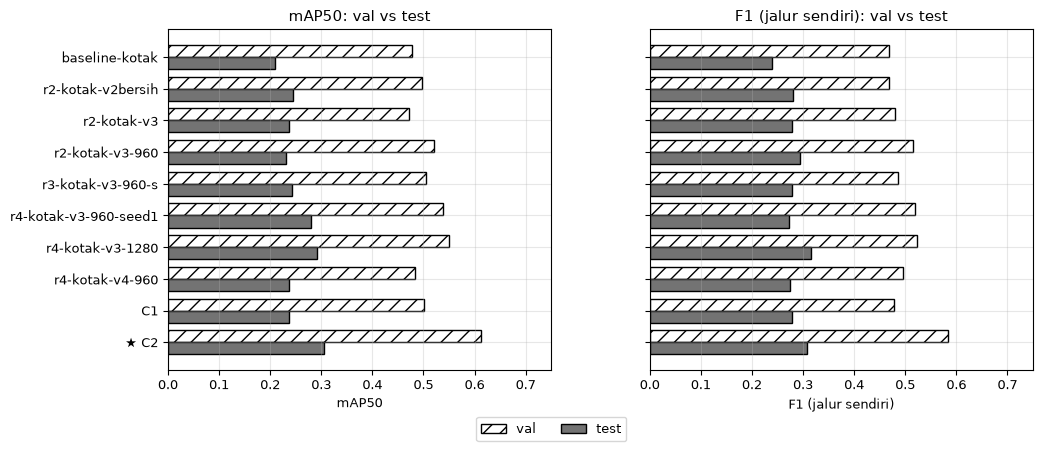

Model,mAP50 val,mAP50 test,Selisih,F1 val,F1 test,Selisih
baseline-kotak,0.478,0.209,-0.269 (-56%),0.468,0.239,-0.229 (-49%)
r2-kotak-v2bersih,0.497,0.244,-0.252 (-51%),0.469,0.280,-0.189 (-40%)
r2-kotak-v3,0.471,0.237,-0.234 (-50%),0.481,0.278,-0.203 (-42%)
r2-kotak-v3-960,0.520,0.231,-0.289 (-56%),0.516,0.294,-0.222 (-43%)
r3-kotak-v3-960-s,0.505,0.243,-0.262 (-52%),0.485,0.279,-0.207 (-43%)
r4-kotak-v3-960-seed1,0.538,0.280,-0.257 (-48%),0.518,0.273,-0.246 (-47%)
r4-kotak-v3-1280,0.550,0.292,-0.257 (-47%),0.524,0.315,-0.209 (-40%)
r4-kotak-v4-960,0.484,0.237,-0.247 (-51%),0.495,0.275,-0.220 (-44%)
C1,0.501,0.236,-0.264 (-53%),0.477,0.279,-0.198 (-41%)
★ C2,0.613,0.305,-0.307 (-50%),0.583,0.308,-0.275 (-47%)


In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.6), sharey=True)
urut = KOTAK[::-1]
yy = np.arange(len(urut)); h = 0.38
for ax, (kunci_m, judul) in zip(axs, (("mAP50", "mAP50"), ("F1", "F1 (jalur sendiri)"))):
    ax.barh(yy + h / 2, [VS(n)["jalur_sendiri"][kunci_m] for n in urut], h, color="white", edgecolor="k", hatch="//", label="val")
    ax.barh(yy - h / 2, [TS(n)["jalur_sendiri"][kunci_m] for n in urut], h, color="0.45", edgecolor="k", label="test")
    ax.set_yticks(yy); ax.set_yticklabels([("★ " if n == FINAL_K else "") + n for n in urut]); ax.set_xlabel(judul); ax.set_title(f"{judul}: val vs test"); ax.set_xlim(0, 0.75)
axs[0].legend(loc="upper center", bbox_to_anchor=(1.0, -0.12), ncol=2)
fig.tight_layout(); plt.show()

baris = []
for n in KOTAK:
    mv, mt_t = VS(n)["jalur_sendiri"]["mAP50"], TS(n)["jalur_sendiri"]["mAP50"]
    fv, ft = VS(n)["jalur_sendiri"]["F1"], TS(n)["jalur_sendiri"]["F1"]
    baris.append([("★ " if n == FINAL_K else "") + n, f3(mv), f3(mt_t), f"{mt_t - mv:+.3f} ({100 * (mt_t - mv) / mv:+.0f}%)", f3(fv), f3(ft), f"{ft - fv:+.3f} ({100 * (ft - fv) / fv:+.0f}%)"])
tabel(["Model", "mAP50 val", "mAP50 test", "Selisih", "F1 val", "F1 test", "Selisih"], baris, rata_kanan=[1, 2, 3, 4, 5, 6])
rank = lambda nilai, n: 1 + sum(1 for m in KOTAK if nilai(m) > nilai(n))
rv_m, rt_m = rank(lambda m: VS(m)["jalur_sendiri"]["mAP50"], "C2"), rank(lambda m: TS(m)["jalur_sendiri"]["mAP50"], "C2")
rv_f, rt_f = rank(lambda m: VS(m)["jalur_sendiri"]["F1"], "C2"), rank(lambda m: TS(m)["jalur_sendiri"]["F1"], "C2")
turun_rata = np.mean([TS(n)["jalur_sendiri"]["mAP50"] / VS(n)["jalur_sendiri"]["mAP50"] for n in KOTAK])

In [17]:
print("Winner's curse: keunggulan C2 atas final sebelumnya (r2-kotak-v3-960), val vs test")
def sel(fn):
    return fn("C2") - fn(PEMBANDING)
baris = [
    ["mAP50", f"{sel(lambda n: VS(n)['jalur_sendiri']['mAP50']):+.3f}", f"{sel(lambda n: TS(n)['jalur_sendiri']['mAP50']):+.3f}"],
    ["F1", f"{sel(lambda n: VS(n)['jalur_sendiri']['F1']):+.3f}", f"{sel(lambda n: TS(n)['jalur_sendiri']['F1']):+.3f}"],
    ["TP @0,25", f"{sel(lambda n: VS(n)['conf025']['total']['tp']):+d}", f"{sel(lambda n: TS(n)['conf025']['total']['tp']):+d}"],
    ["FP @0,25", f"{sel(lambda n: VS(n)['conf025']['total']['fp']):+d}", f"{sel(lambda n: TS(n)['conf025']['total']['fp']):+d}"],
]
tabel(["Selisih C2 - r2-kotak-v3-960", "Val", "Test"], baris, rata_kanan=[1, 2])

print()
print("Susunan kelas (jumlah instance) val vs test, dan C2 di tiap lokasi (ambang terkunci):")
nv = {k: kk_v[k]["n"] for k in NAMES}; nt = {k: pk[k]["n"] for k in NAMES}
sv, st_ = sum(nv.values()), sum(nt.values())
tabel(["Kelas", "n val", "porsi val", "n test", "porsi test"], [[k, nv[k], f"{100 * nv[k] / sv:.0f}%", nt[k], f"{100 * nt[k] / st_:.0f}%"] for k in NAMES], rata_kanan=[1, 2, 3, 4])
baris = []
for tag, ds, sns in (("val", VS, [s for s in V["C2"]["subset"] if s not in ("semua", "dada", "mata")]), ("test", TS, ["lantai11", "taman-ubm"])):
    for sn in sns:
        a = ds("C2", sn)["ambang_terkunci"]
        baris.append([tag, sn, ds("C2", sn)["n_frame"], tpfpfn(a["total"]), f"{a['fp_per_frame']:.2f}", rs(a["recall"]["dekat"]), f3(a["P_mikro"], 2), f3(a["R_mikro"], 2)])
tabel(["Set", "Lokasi", "Frame", "TP/FP/FN", "FP/frame", "Recall dekat", "Precision", "Recall"], baris, rata_kanan=[2, 4, 6, 7])

Winner's curse: keunggulan C2 atas final sebelumnya (r2-kotak-v3-960), val vs test


Selisih C2 - r2-kotak-v3-960,Val,Test
mAP50,+0.092,+0.074
F1,+0.067,+0.014
"TP @0,25",+4,+9
"FP @0,25",-62,-12



Susunan kelas (jumlah instance) val vs test, dan C2 di tiap lokasi (ambang terkunci):


Kelas,n val,porsi val,n test,porsi test
pilar,34,13%,38,16%
pohon,10,4%,3,1%
tepian,45,17%,51,22%
orang,29,11%,32,14%
tanaman_pot,10,4%,99,42%
kursi,22,8%,14,6%
kendaraan,108,41%,0,0%
tangga,5,2%,0,0%


Set,Lokasi,Frame,TP/FP/FN,FP/frame,Recall dekat,Precision,Recall
val,dapsut,26,126/67/101,2.58,28/61 (0.46),0.65,0.56
val,perpus-lt9-ubm-tower,12,18/5/12,0.42,6/7 (0.86),0.78,0.60
val,tangga-naik-lt9-lt10-ubm-tower,16,6/4/0,0.25,4/4 (1.00),0.60,1.00
test,lantai11,45,37/6/47,0.13,12/36 (0.33),0.86,0.44
test,taman-ubm,46,40/97/113,2.11,9/32 (0.28),0.29,0.26


In [18]:
tidak_ada_test = [k for k in NAMES if nt[k] == 0 and nv[k] > 0]
bagian_veh = 100 * sum(nv[k] for k in tidak_ada_test) / sv
dom_t = max(NAMES, key=lambda k: nt[k])
fp_lok_v = [VS("C2", s)["ambang_terkunci"]["fp_per_frame"] for s in V["C2"]["subset"] if s not in ("semua", "dada", "mata")]
fp_lok_t = [TS("C2", s)["ambang_terkunci"]["fp_per_frame"] for s in ("lantai11", "taman-ubm")]
r1280_gain = (TS("r4-kotak-v3-1280")["jalur_sendiri"]["F1"], TS("C2")["jalur_sendiri"]["F1"])
display(Markdown(
    f"**Bacaan.** (1) **Penurunan nyata dan besar**: rata-rata mAP50 semua model kotak di test hanya {100 * turun_rata:.0f}% dari val; untuk C2, mAP50 {f3(VS('C2')['jalur_sendiri']['mAP50'])} turun ke {f3(TS('C2')['jalur_sendiri']['mAP50'])} dan F1 {f3(VS('C2')['jalur_sendiri']['F1'])} ke {f3(TS('C2')['jalur_sendiri']['F1'])}. "
    f"(2) **Domain gap**: susunan kelas berbeda jauh. Kelas yang ada di val tetapi tidak di test ({', '.join(tidak_ada_test)}) menyumbang {bagian_veh:.0f}% instance val; di test kelas terbanyak adalah {dom_t} ({100 * nt[dom_t] / st_:.0f}% instance, val: {100 * nv[dom_t] / sv:.0f}%). "
    f"Kotak salah per frame juga sangat bergantung lokasi: di antara lokasi val {min(fp_lok_v):.2f}-{max(fp_lok_v):.2f}, di test {min(fp_lok_t):.2f}-{max(fp_lok_t):.2f}. Jadi rata-rata val dan test tidak mengukur kelas yang sama, dan dua lokasi test tidak mewakili 'tempat baru' pada umumnya. "
    f"(3) **Kutukan pemenang**: C2 peringkat {rv_m} di val dan {rt_m} di test untuk mAP50, tetapi peringkat {rv_f} di val dan {rt_f} di test untuk F1. Keunggulan atas final sebelumnya menyusut atau bergeser: mAP50 {sel(lambda n: VS(n)['jalur_sendiri']['mAP50']):+.3f} (val) vs {sel(lambda n: TS(n)['jalur_sendiri']['mAP50']):+.3f} (test), "
    f"F1 {sel(lambda n: VS(n)['jalur_sendiri']['F1']):+.3f} vs {sel(lambda n: TS(n)['jalur_sendiri']['F1']):+.3f}, FP {sel(lambda n: VS(n)['conf025']['total']['fp']):+d} vs {sel(lambda n: TS(n)['conf025']['total']['fp']):+d}. "
    f"Model tunggal `r4-kotak-v3-1280`, yang gagal aturan val, mencapai F1 test {f3(r1280_gain[0])} (C2: {f3(r1280_gain[1])}). Itu tidak mengubah pilihan (aturan: tidak ada hasil test yang mengubah model), dan satu test set 91 frame tidak membuktikan 1280 lebih baik. "
    "Yang bisa dikatakan jujur: angka test C2 adalah perkiraan yang tidak bias karena test tidak dipakai memilih apa pun; angka val C2 tidak."))

**Bacaan.** (1) **Penurunan nyata dan besar**: rata-rata mAP50 semua model kotak di test hanya 49% dari val; untuk C2, mAP50 0.613 turun ke 0.305 dan F1 0.583 ke 0.308. (2) **Domain gap**: susunan kelas berbeda jauh. Kelas yang ada di val tetapi tidak di test (kendaraan, tangga) menyumbang 43% instance val; di test kelas terbanyak adalah tanaman_pot (42% instance, val: 4%). Kotak salah per frame juga sangat bergantung lokasi: di antara lokasi val 0.25-2.58, di test 0.13-2.11. Jadi rata-rata val dan test tidak mengukur kelas yang sama, dan dua lokasi test tidak mewakili 'tempat baru' pada umumnya. (3) **Kutukan pemenang**: C2 peringkat 1 di val dan 1 di test untuk mAP50, tetapi peringkat 1 di val dan 2 di test untuk F1. Keunggulan atas final sebelumnya menyusut atau bergeser: mAP50 +0.092 (val) vs +0.074 (test), F1 +0.067 vs +0.014, FP -62 vs -12. Model tunggal `r4-kotak-v3-1280`, yang gagal aturan val, mencapai F1 test 0.315 (C2: 0.308). Itu tidak mengubah pilihan (aturan: tidak ada hasil test yang mengubah model), dan satu test set 91 frame tidak membuktikan 1280 lebih baik. Yang bisa dikatakan jujur: angka test C2 adalah perkiraan yang tidak bias karena test tidak dipakai memilih apa pun; angka val C2 tidak.

## 7. Baseline dan kebocoran taman-ubm
Baseline dilatih dengan sejumlah frame yang memperlihatkan area `taman-ubm` (lihat Notebook 01 dan `docs/test-set.md`), model ronde 2 ke atas tidak. Karena itu perbandingan di taman-ubm **berat sebelah menguntungkan baseline**; lantai 11 tidak terkena.
Tabel ini memisahkan kedua lokasi (conf 0,25, jalur sendiri untuk mAP50).

In [19]:
baris = []
for n in ("baseline-kotak", "r2-kotak-v2bersih", PEMBANDING, "r4-kotak-v3-1280", "C2"):
    a, b = TS(n, "lantai11"), TS(n, "taman-ubm")
    baris.append([("★ " if n == FINAL_K else "") + n, f3(a["jalur_sendiri"]["mAP50"]), tpfpfn(a["conf025"]["total"]), rs(a["conf025"]["recall"]["dekat"]),
                  f3(b["jalur_sendiri"]["mAP50"]), tpfpfn(b["conf025"]["total"]), rs(b["conf025"]["recall"]["dekat"])])
tabel(["Model", "Lantai 11: mAP50", "TP/FP/FN", "dekat", "taman-ubm: mAP50", "TP/FP/FN", "dekat"], baris, rata_kanan=[1, 4])
bt, bl = TS("baseline-kotak", "taman-ubm"), TS("baseline-kotak", "lantai11")
tm_urut = sorted(KOTAK, key=lambda n: TS(n, "taman-ubm")["jalur_sendiri"]["mAP50"])
posisi = tm_urut.index("baseline-kotak") + 1
display(Markdown(
    f"**Bacaan.** Walau diuntungkan, baseline {'adalah yang terendah' if posisi == 1 else 'berada di urutan ke-' + str(posisi) + ' dari bawah'} menurut mAP50 di taman-ubm ({f3(bt['jalur_sendiri']['mAP50'])}; berikutnya `{tm_urut[1]}` {f3(TS(tm_urut[1], 'taman-ubm')['jalur_sendiri']['mAP50'])}) "
    f"dan hanya menemukan {rs(bt['conf025']['recall']['dekat'])} objek dekat di sana, jadi keunggulan model ronde 2 ke atas di luar gedung tampak nyata, tidak habis dijelaskan oleh kebocoran. "
    f"Di lantai 11 baseline setara dengan yang lain (mAP50 {f3(bl['jalur_sendiri']['mAP50'])} vs C2 {f3(TS('C2', 'lantai11')['jalur_sendiri']['mAP50'])}): di dalam gedung, ronde 2 sampai ensemble tidak memberi perbaikan yang terukur. "
    "Kelemahan: pembersihan kebocoran hanya menangkap kemiripan visual (lihat Notebook 01), dan baseline tidak dilatih ulang."))

Model,Lantai 11: mAP50,TP/FP/FN,dekat,taman-ubm: mAP50,TP/FP/FN,dekat
baseline-kotak,0.405,38/33/46,13/36 (0.36),0.204,28/112/125,1/32 (0.03)
r2-kotak-v2bersih,0.388,38/22/46,13/36 (0.36),0.249,42/97/111,11/32 (0.34)
r2-kotak-v3-960,0.358,32/18/52,10/36 (0.28),0.229,39/105/114,8/32 (0.25)
r4-kotak-v3-1280,0.388,41/25/43,13/36 (0.36),0.315,54/111/99,7/32 (0.22)
★ C2,0.401,40/19/44,13/36 (0.36),0.329,40/92/113,9/32 (0.28)


**Bacaan.** Walau diuntungkan, baseline adalah yang terendah menurut mAP50 di taman-ubm (0.204; berikutnya `C1` 0.224) dan hanya menemukan 1/32 (0.03) objek dekat di sana, jadi keunggulan model ronde 2 ke atas di luar gedung tampak nyata, tidak habis dijelaskan oleh kebocoran. Di lantai 11 baseline setara dengan yang lain (mAP50 0.405 vs C2 0.401): di dalam gedung, ronde 2 sampai ensemble tidak memberi perbaikan yang terukur. Kelemahan: pembersihan kebocoran hanya menangkap kemiripan visual (lihat Notebook 01), dan baseline tidak dilatih ulang.

## 8. Matriks konfusi C2 di test (dihitung ulang dari prediksi tersimpan)
**Ini bukan evaluasi baru.** Prediksi C2 pada test sudah tersimpan (`data/test-final/t1/pred_C2.pkl`, conf anggota 0,05 lalu WBF) dan dipakai apa adanya dengan ambang per kelas terkunci dari val. Pencocokan kotak memakai fungsi yang sama dengan `tools/test_t1.py`
(`test_final.hitung` -> `evaluasi_baseline.cocokkan_kotak`). Syarat sebelum matriks ditampilkan: TP/FP/FN yang dihitung harus **persis sama** dengan yang tercatat di `t1/C2.json` (dan frame-level yang tercatat); jika berbeda, matriks tidak dibuat.
Baris/kolom *latar*: kolom latar = objek GT yang terlewat (FN), baris latar = kotak prediksi tanpa GT (FP). Kasus kotak salah kelas yang menimpa GT kelas lain tetap dihitung sebagai FP dan FN (sama dengan jalur kode yang dicatat) dan dilaporkan terpisah.

Dari prediksi tersimpan: TP/FP/FN = 77/103/160; tercatat (t1/C2.json) = 77/103/160 -> COCOK PERSIS
Frame-level dihitung: 29/0/14/48; tercatat: 29/0/14/48 -> COCOK PERSIS


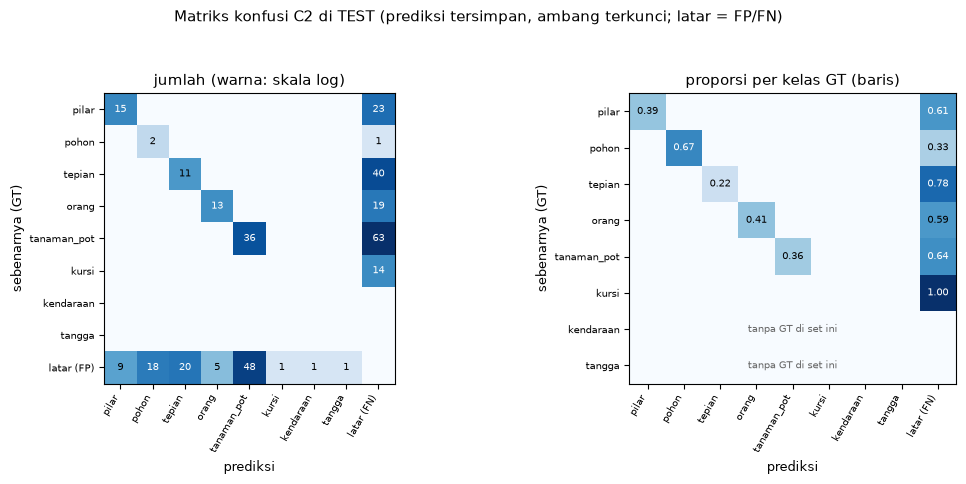

In [20]:
PRED_T = pickle.loads((TF / "t1/pred_C2.pkl").read_bytes())
M_T, tot_t, tukar_t = bangun_cm(NAMA_K, IMGS_TEST, LAB_TEST, PRED_T["c005"], AMB_ID)
cat_t = a_all["total"]
fr_hitung, _ = mt.level_frame(IMGS_TEST, LAB_TEST, PRED_T["c005"], AMB_ID)
cocok_total = (tot_t["tp"], tot_t["fp"], tot_t["fn"]) == (cat_t["tp"], cat_t["fp"], cat_t["fn"])
cocok_frame = all(fr_hitung[k] == a_all["frame"][k] for k in ("TP", "FP", "FN", "TN"))
print(f"Dari prediksi tersimpan: TP/FP/FN = {tot_t['tp']}/{tot_t['fp']}/{tot_t['fn']}; tercatat (t1/C2.json) = {cat_t['tp']}/{cat_t['fp']}/{cat_t['fn']} -> {'COCOK PERSIS' if cocok_total else 'BEDA'}")
print(f"Frame-level dihitung: {fr_hitung['TP']}/{fr_hitung['FP']}/{fr_hitung['FN']}/{fr_hitung['TN']}; tercatat: {a_all['frame']['TP']}/{a_all['frame']['FP']}/{a_all['frame']['FN']}/{a_all['frame']['TN']} -> {'COCOK PERSIS' if cocok_frame else 'BEDA'}")
CM_DIBUAT = bool(cocok_total and cocok_frame)
if CM_DIBUAT:
    gambar_cm(M_T, NAMES, "Matriks konfusi C2 di TEST (prediksi tersimpan, ambang terkunci; latar = FP/FN)")
else:
    print("Matriks konfusi TIDAK dibuat karena angka tidak cocok persis; tidak ada penyesuaian.")

In [21]:
if CM_DIBUAT:
    fn_t = {NAMES[i]: int(M_T[i, n_]) for i in range(n_)}
    fp_t = {NAMES[i]: int(M_T[n_, i]) for i in range(n_)}
    gt_t = {NAMES[i]: int(M_T[i].sum()) for i in range(n_)}
    rec_t = {k: (M_T[i, i] / gt_t[k] if gt_t[k] else None) for i, k in enumerate(NAMES)}
    fp_top_t = sorted(fp_t, key=fp_t.get, reverse=True)[:2]
    fn_top_t = sorted(fn_t, key=fn_t.get, reverse=True)[:2]
    ket_tt = ", ".join(a + " diprediksi " + b + ": " + str(c) for (a, b), c in tukar_t.items()) or "tidak ada"
    sel_agn = a_all["agnostik"]["tp"] - a_all["total"]["tp"]
    kursi_tuk = sum(c for (a, b), c in tukar_t.items() if a == "kursi")
    ket_kursi = ", ".join(b + ": " + str(c) for (a, b), c in tukar_t.items() if a == "kursi") or "tidak ada"
    display(Markdown(
        f"**Bacaan.** Kegagalan di test terutama berupa **objek terlewat** ({tot_t['fn']} FN, {100 * tot_t['fn'] / (tot_t['tp'] + tot_t['fn']):.0f}% dari {tot_t['tp'] + tot_t['fn']} objek) dan **kotak latar** ({tot_t['fp']} FP), bukan salah kelas: "
        f"hanya {sum(tukar_t.values())} kotak salah yang menimpa GT kelas lain ({ket_tt}). Konsisten dengan itu, mengabaikan kelas hanya menambah {sel_agn} TP (TP class-agnostic {a_all['agnostik']['tp']} vs {a_all['total']['tp']} per kelas). "
        f"FN terbanyak: {fn_top_t[0]} ({fn_t[fn_top_t[0]]} dari {gt_t[fn_top_t[0]]}) dan {fn_top_t[1]} ({fn_t[fn_top_t[1]]} dari {gt_t[fn_top_t[1]]}); FP terbanyak: {fp_top_t[0]} ({fp_t[fp_top_t[0]]}) dan {fp_top_t[1]} ({fp_t[fp_top_t[1]]}). "
        f"Kursi: {int(M_T[NAMES.index('kursi'), NAMES.index('kursi')])} dari {gt_t['kursi']} ditemukan; {kursi_tuk} kotak berkelas lain menimpa GT kursi ({ket_kursi}), jadi kursi bukan hanya tidak terdeteksi tetapi sesekali dibaca sebagai kelas lain. "
        "Kelemahan: ini satu model pada satu set 91 frame dengan ambang dari val; barisnya yang kosong (kendaraan, tangga) berarti tidak ada GT, bukan berarti model benar."))

**Bacaan.** Kegagalan di test terutama berupa **objek terlewat** (160 FN, 68% dari 237 objek) dan **kotak latar** (103 FP), bukan salah kelas: hanya 5 kotak salah yang menimpa GT kelas lain (kursi diprediksi kendaraan: 1, kursi diprediksi tangga: 1, pilar diprediksi tanaman_pot: 1, kursi diprediksi tepian: 2). Konsisten dengan itu, mengabaikan kelas hanya menambah 4 TP (TP class-agnostic 81 vs 77 per kelas). FN terbanyak: tanaman_pot (63 dari 99) dan tepian (40 dari 51); FP terbanyak: tanaman_pot (48) dan tepian (20). Kursi: 0 dari 14 ditemukan; 4 kotak berkelas lain menimpa GT kursi (kendaraan: 1, tangga: 1, tepian: 2), jadi kursi bukan hanya tidak terdeteksi tetapi sesekali dibaca sebagai kelas lain. Kelemahan: ini satu model pada satu set 91 frame dengan ambang dari val; barisnya yang kosong (kendaraan, tangga) berarti tidak ada GT, bukan berarti model benar.

## 9. Contoh kualitatif
Dua lembar gambar yang sudah tersimpan (wajah sudah diburamkan di data). Pertama: contact sheet **test** untuk C2, frame yang dipilih berdasarkan skor per frame (judul tiap sel memuat lokasi dan skor; di tiap sel kiri = GT, kanan = prediksi, warna mengikuti kelas).
Kedua: contoh **val** model lama (r2) vs TTA vs ensemble final. Gambar diperkecil hingga lebar <= 1000 px.

C2_kontak_16.jpg (TEST), ukuran asli: (1976, 1796)


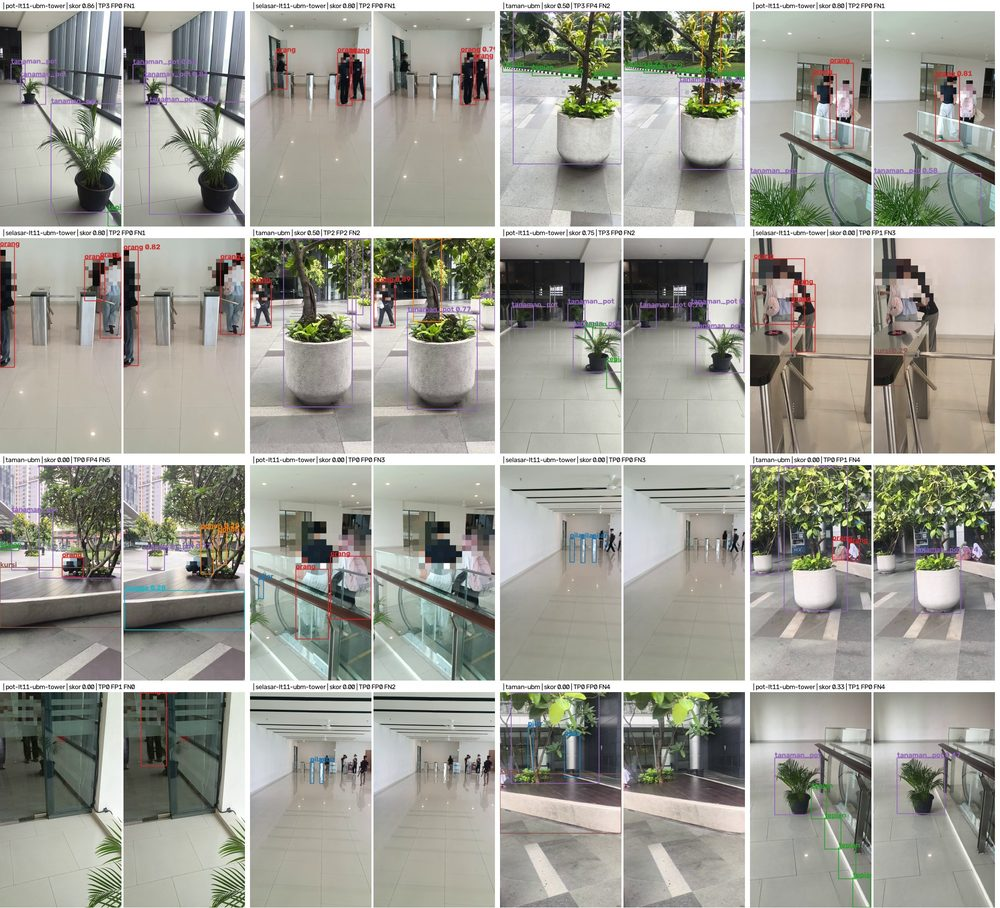

In [22]:
p1 = ROOT / "runs/test-final/C2_kontak_16.jpg"
cek_putih(p1)
im1 = Image.open(p1)
print("C2_kontak_16.jpg (TEST), ukuran asli:", im1.size)
tampil_jpeg(im1, lebar=1000)

before_after_val.jpg (VAL), ukuran asli: (1230, 3282)


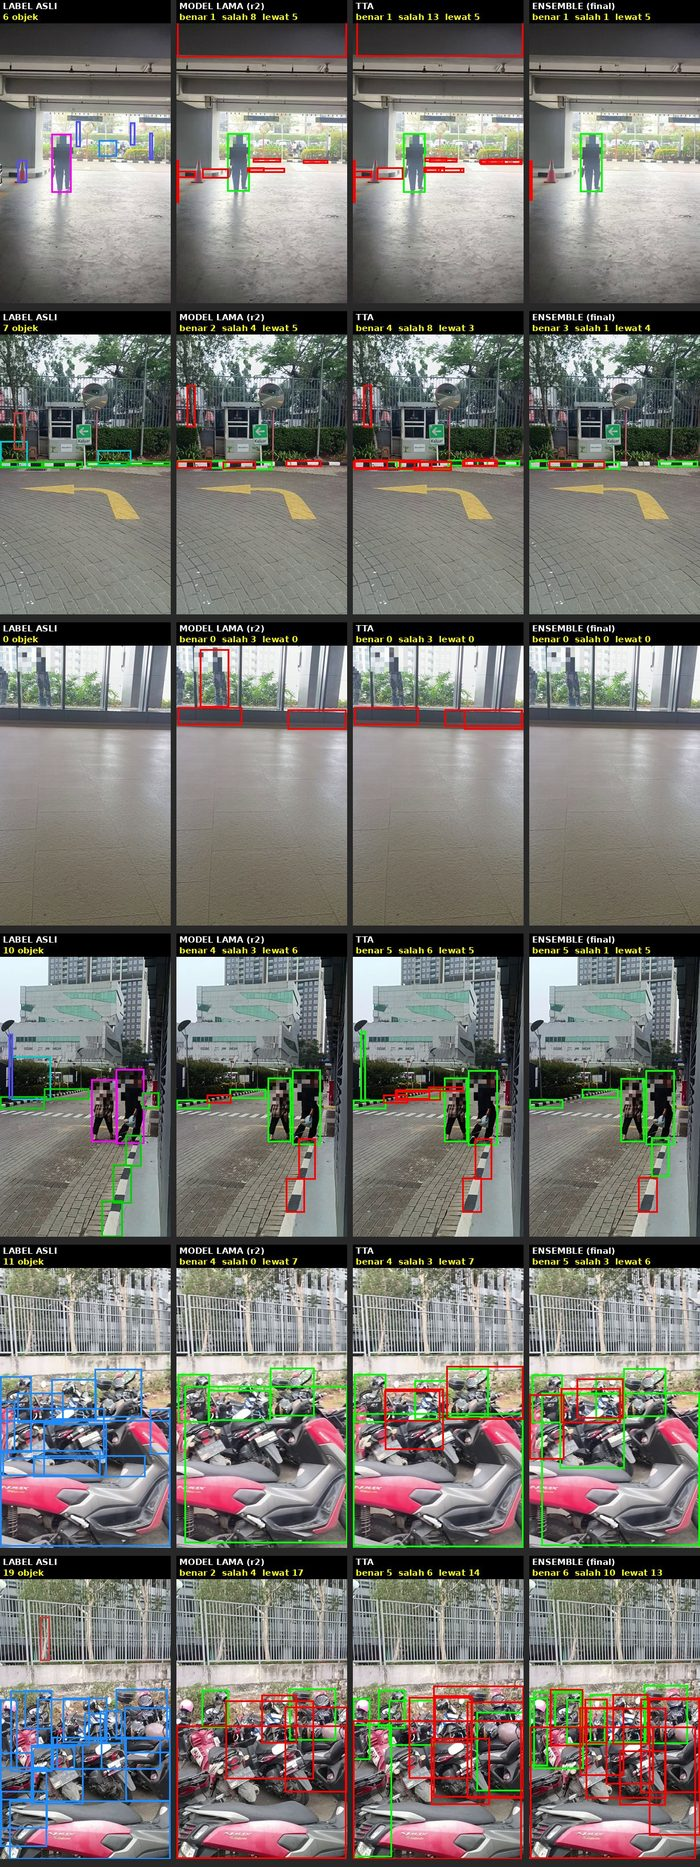

**Bacaan.** Lembar test menunjukkan pola yang sama dengan angka: pot dan orang di dalam gedung sering benar, sedangkan di taman banyak objek terlewat dan ada kotak salah (mis. batang pohon, bangku). Lembar val menunjukkan manfaat ensemble di frame yang ramai (jauh lebih sedikit kotak salah daripada model lama), tetapi juga bahwa barisan motor rapat tetap kewalahan. Kelemahan: frame pada lembar dipilih (terbaik dan terburuk, atau contoh), jadi tidak mewakili rata-rata.

In [23]:
p2 = ROOT / "data/test-final/before_after_val.jpg"
cek_putih(p2)
im2 = Image.open(p2)
print("before_after_val.jpg (VAL), ukuran asli:", im2.size)
tampil_jpeg(im2, lebar=700)
display(Markdown(
    "**Bacaan.** Lembar test menunjukkan pola yang sama dengan angka: pot dan orang di dalam gedung sering benar, sedangkan di taman banyak objek terlewat dan ada kotak salah (mis. batang pohon, bangku). "
    "Lembar val menunjukkan manfaat ensemble di frame yang ramai (jauh lebih sedikit kotak salah daripada model lama), tetapi juga bahwa barisan motor rapat tetap kewalahan. "
    "Kelemahan: frame pada lembar dipilih (terbaik dan terburuk, atau contoh), jadi tidak mewakili rata-rata."))

## 10. Keterbatasan
Angka di bawah dihitung dari berkas yang sama dengan bagian sebelumnya.

In [24]:
nf = TS("C2")["n_frame"]
n_lok = len({p.stem.split("_20")[0] for p in IMGS_TEST})
n_box = a_all["total"]["tp"] + a_all["total"]["fn"]
tanpa = [k for k in NAMES if pk[k]["n"] == 0]
kurang20 = [(k, pk[k]["n"]) for k in NAMES if 0 < pk[k]["n"] < ar["n_min"]]
tep_d = rk["tepian"]["dekat"]; kur = rk["kursi"]["dekat"]; kur_all = pk["kursi"]
iou_jk = max(TS(n)["iou_piksel_per_kelas"]["jalan_kendaraan"] for n in SEG)
baris = [
    ["Ukuran test", f"{nf} frame, {n_box} kotak, {n_lok} lokasi (satu hari rekaman per lokasi)"],
    ["Ukuran val (dipakai memilih model dan ambang)", f"{VS('C2')['n_frame']} frame, {sum(nv.values())} kotak"],
    ["Kelas tanpa instance di test", ", ".join(tanpa) + " (kotak); tangga juga 0 di segmentasi"],
    ["Kelas dengan n < " + str(ar["n_min"]) + " di test", ", ".join(f"{k} ({n})" for k, n in kurang20)],
    ["Kursi di test (C2, ambang terkunci)", f"{kur_all['tp']} dari {kur_all['n']} ditemukan"],
    ["Tepian dekat di test (C2, ambang terkunci)", f"{tep_d['ditemukan']} dari {tep_d['gt']} ditemukan"],
    ["jalan_kendaraan segmentasi (IoU piksel tertinggi dari 3 model)", f"{iou_jk:.3f}"],
    ["Penurunan mAP50 C2 val ke test", f"{f3(VS('C2')['jalur_sendiri']['mAP50'])} -> {f3(TS('C2')['jalur_sendiri']['mAP50'])}"],
    ["Frame positif untuk recall peringatan frame", f"{a_all['frame']['TP'] + a_all['frame']['FN']} dari {nf} frame"],
    ["Selisih mAP50 C2 vs model tunggal terbaik kedua", f"{sel_c2_1280:+.3f}"],
]
tabel(["Keterbatasan", "Angka (dihitung)"], baris)

Keterbatasan,Angka (dihitung)
Ukuran test,"91 frame, 237 kotak, 3 lokasi (satu hari rekaman per lokasi)"
Ukuran val (dipakai memilih model dan ambang),"54 frame, 263 kotak"
Kelas tanpa instance di test,"kendaraan, tangga (kotak); tangga juga 0 di segmentasi"
Kelas dengan n < 20 di test,"pohon (3), kursi (14)"
"Kursi di test (C2, ambang terkunci)",0 dari 14 ditemukan
"Tepian dekat di test (C2, ambang terkunci)",0 dari 22 ditemukan
jalan_kendaraan segmentasi (IoU piksel tertinggi dari 3 model),0.028
Penurunan mAP50 C2 val ke test,0.613 -> 0.305
Frame positif untuk recall peringatan frame,43 dari 91 frame
Selisih mAP50 C2 vs model tunggal terbaik kedua,+0.013


- **Test kecil dan hanya dua lokasi.** Selisih antar model di bawah margin derau tidak bisa dibedakan; dua lokasi tidak mewakili semua tempat. Satu hari rekaman per lokasi (cuaca dan pencahayaan terbatas).
- **Kelas tanpa atau dengan sedikit instance di test.** Kendaraan dan tangga tidak terukur di lokasi baru; pohon dan kursi hanya belasan instance atau kurang, sehingga AP-nya sangat berisik. `jalan_kendaraan` hanya di beberapa frame taman.
- **Kegagalan yang spesifik tetapi penting.** Kursi (bangku taman) tidak dikenali sama sekali dan tepian dekat tidak ditemukan; keduanya relevan untuk keselamatan pengguna.
- **Val optimistis dan dipakai berulang.** Model, ambang, dan ensemble dipilih di val kecil yang sama (winner's curse); angka val tidak boleh dibaca sebagai kemampuan nyata. Angka test adalah perkiraan yang tidak bias, tetapi dari sampel kecil.
- **Ambang disetel pada val** dengan conf anggota 0,001 sedangkan app memakai 0,05; di test efek perbedaan itu tidak diperiksa terpisah.
- **Label test mengikuti aturan v1.7**, label latih terbaru v1.8; sebagian kotak salah tanaman_pot di taman bisa berasal dari perbedaan aturan (tidak diperiksa satu per satu).
- **"Dekat" adalah heuristik posisi** (tepi bawah kotak), bukan jarak sebenarnya; peringatan frame memakai heuristik yang sama.
- **Matriks konfusi test adalah penilaian ulang prediksi tersimpan**, bukan evaluasi baru, dan memakai pencocokan yang sama dengan yang dicatat.
- **Baseline bocor di taman-ubm** (Notebook 01); kecepatan diukur di GPU laptop, bukan HP atau server app.

## 11. Pemeriksaan angka acuan
Tabel ini membandingkan angka hitungan notebook dengan angka yang tercatat di dokumen proyek. Angka hanya dilaporkan sesuai hasil hitung; tidak ada yang disesuaikan agar cocok.
Pembulatan 3 desimal (IoU piksel baseline-seg: acuan "sekitar 0,86", dibandingkan pada 2 desimal).

In [25]:
vC2 = VS("C2"); tC2 = TS("C2")
cek = [
    ("Val C2 mAP50", 0.613, round(vC2["jalur_sendiri"]["mAP50"], 3), 0),
    ("Val C2 F1", 0.583, round(vC2["jalur_sendiri"]["F1"], 3), 0),
    ("Val C2 ambang terkunci TP/FP/FN", "150/76/113", tpfpfn(vC2["ambang_terkunci"]["total"]), 0),
    ("Val model tunggal terbaik r2-kotak-v3-960, mAP50 (tabel Ultralytics)", 0.537, round(V[PEMBANDING]["ultralytics"]["box"]["mAP50"], 3), 0),
    ("Val r2-kotak-v3-960, F1 (tabel Ultralytics)", 0.532, round(V[PEMBANDING]["ultralytics"]["box"]["F1"], 3), 0),
    ("Test C2 mAP50", 0.305, round(tC2["jalur_sendiri"]["mAP50"], 3), 0),
    ("Test C2 mAP50-95", 0.172, round(tC2["jalur_sendiri"]["mAP50_95"], 3), 0),
    ("Test C2 F1", 0.308, round(tC2["jalur_sendiri"]["F1"], 3), 0),
    ("Test C2 ambang terkunci TP/FP/FN", "77/103/160", tpfpfn(tC2["ambang_terkunci"]["total"]), 0),
    ("Frame-level C2: FP dari frame tanpa rintangan", "0 dari 48", f"{fk['FP']} dari {fk['FP'] + fk['TN']}", 0),
    ("Frame-level C2: recall (TP / frame positif)", "29/43", f"{fk['TP']}/{fk['TP'] + fk['FN']}", 0),
    ("Test baseline-kotak mAP50", 0.209, round(TS("baseline-kotak")["jalur_sendiri"]["mAP50"], 3), 0),
    ("Test r4-kotak-v3-1280 mAP50", 0.292, round(TS("r4-kotak-v3-1280")["jalur_sendiri"]["mAP50"], 3), 0),
    ("Test r4-kotak-v3-1280 F1", 0.315, round(TS("r4-kotak-v3-1280")["jalur_sendiri"]["F1"], 3), 0),
    ("Seg jalur_jalan IoU, r2-seg-v3", 0.809, round(iou_f["jalur_jalan"], 3), 0),
    ("Seg jalur_jalan IoU, baseline-seg (sekitar 0,86)", 0.86, round(iou_b["jalur_jalan"], 2), 0),
    ("Seg jalan_kendaraan IoU <= 0,03 (maksimum 3 model)", "<= 0.03", round(iou_jk, 3), "kurang"),
    ("Matriks konfusi test: TP/FP/FN dihitung ulang", "77/103/160", f"{tot_t['tp']}/{tot_t['fp']}/{tot_t['fn']}", 0),
]
baris, beda = [], []
for nama, e, h, mode in cek:
    ok = (h <= 0.03 + 1e-12) if mode == "kurang" else (e == h)
    if not ok:
        beda.append(nama)
    baris.append([nama, e, h, "OK" if ok else "BEDA"])
tabel(["Angka acuan", "Diharapkan", "Dihitung", "Status"], baris, rata_kanan=[1, 2])
print("Angka yang berbeda dari acuan:", beda or "tidak ada")
print()
print("Gambar berkas yang ditampilkan di notebook ini:")
for g in GAMBAR_TAMPIL:
    print(" -", g)
print("Grafik lain dibuat oleh matplotlib dari JSON/CSV/pickle (bukan berkas gambar).")
print()
print("Matriks konfusi test diproduksi:", CM_DIBUAT, f"| TP/FP/FN direproduksi: {tot_t['tp']}/{tot_t['fp']}/{tot_t['fn']}")

Angka acuan,Diharapkan,Dihitung,Status
Val C2 mAP50,0.613,0.613,OK
Val C2 F1,0.583,0.583,OK
Val C2 ambang terkunci TP/FP/FN,150/76/113,150/76/113,OK
"Val model tunggal terbaik r2-kotak-v3-960, mAP50 (tabel Ultralytics)",0.537,0.537,OK
"Val r2-kotak-v3-960, F1 (tabel Ultralytics)",0.532,0.532,OK
Test C2 mAP50,0.305,0.305,OK
Test C2 mAP50-95,0.172,0.172,OK
Test C2 F1,0.308,0.308,OK
Test C2 ambang terkunci TP/FP/FN,77/103/160,77/103/160,OK
Frame-level C2: FP dari frame tanpa rintangan,0 dari 48,0 dari 48,OK


Angka yang berbeda dari acuan: tidak ada

Gambar berkas yang ditampilkan di notebook ini:
 - runs/ronde2/r2-kotak-v3-960/confusion_matrix_normalized.png
 - runs/test-final/C2_kontak_16.jpg
 - data/test-final/before_after_val.jpg
Grafik lain dibuat oleh matplotlib dari JSON/CSV/pickle (bukan berkas gambar).

Matriks konfusi test diproduksi: True | TP/FP/FN direproduksi: 77/103/160
